# Assignment_A1

Compare Convolutional Neural Networks (CNN family - ResNet-50) and Vision Transformers (ViT-B/16) on a large image dataset, evaluated across multiple training regimes:

From-scratch vs. Pre-trained

Freeze full backbone

Partial freeze

Full fine-tune

## Device detection

In [2]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Program using device: {device}")

Program using device: cuda


## User definition

#### Define global path

    - datapath
    - datapath_train
    - datapath_val
    - datapath_test
    - path_json

In [3]:
datapath = "./data/imagenet100/"
datapath_train = datapath + "train/"
datapath_val = datapath + "val/"
datapath_test = datapath + "test/"
path_json = datapath + "Labels.json"

In [4]:
import os

os.makedirs(datapath, exist_ok=True)
os.makedirs(datapath_test, exist_ok=True)

#### Specific infor

##### Template

In [ ]:
# use this format for all model

model_infor_template = {
    "backbone": None,
    "fine-tune": None,
    "head": None,
    "opt": None,
    "scheduler": None, # step, cosine
    "train_type": None, # new, resume, no
    "epoch_new": 0,
    "epoch_resume": 0, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : None, # set path if "train_type" is "resume"
    "json_path": None
}

history_template = {
    "epoch": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr_bb": [], "lr_head": []
}

result_template = {
    "test_acc": 0.0, "test_loss": 0.0,
    "train_time": 0.0,
    "test_time": 0.0,
    "tp": 0, "tn": 0, "fp": 0, "fn": 0, "f1_score": 0.0,
    "total_params": 0, "trainable_params": 0
}

##### Resnet50 pretrained, freeze full backbone

In [6]:
import copy

model_infor_rn50_pt_fb = copy.deepcopy(model_infor_template)
model_infor_rn50_pt_fb.update({
    "backbone": "resnet50",
    "fine-tune": "freezefull",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "new", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 50, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : None, # set path if "train_type" is "resume"
    "json_path": "./models/result_rn50_pt_fb.json"
})

history_rn50_pt_fb = copy.deepcopy(history_template)
result_rn50_pt_fb = copy.deepcopy(result_template)

##### Resnet50 pretrained, freeze partial block

In [7]:
import copy

model_infor_rn50_pt_fp = copy.deepcopy(model_infor_template)
model_infor_rn50_pt_fp.update({
    "backbone": "resnet50",
    "fine-tune": "partial",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "new", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 50, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : None,
    "json_path": "./models/result_rn50_pt_fp.json"
})

history_rn50_pt_fp = copy.deepcopy(history_template)
result_rn50_pt_fp = copy.deepcopy(result_template)

##### Resnet50 pretrained, fine-tune

In [ ]:
import copy

model_infor_rn50_pt_ft = copy.deepcopy(model_infor_template)
model_infor_rn50_pt_ft.update({
    "backbone": "resnet50",
    "fine-tune": "scratch",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "new", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 20, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : "./models/last_rn50_pt_ft_model.pth",
    "json_path": "./models/result_rn50_pt_ft.json"
})

history_rn50_pt_ft = copy.deepcopy(history_template)
result_rn50_pt_ft = copy.deepcopy(result_template)

##### Resnet50 from Scratch

In [181]:
import copy

model_infor_rn50_fs = copy.deepcopy(model_infor_template)
model_infor_rn50_fs.update({
    "backbone": "resnet50",
    "fine-tune": "fine-tune",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "new", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 50, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : None,
    "json_path": "./models/result_rn50_fs.json"
})

history_rn50_fs = copy.deepcopy(history_template)
result_rn50_fs = copy.deepcopy(result_template)

##### ViT-B/16 pretrained, freeze full backbone

In [10]:
import copy

model_infor_vitb16_pt_fb = copy.deepcopy(model_infor_template)
model_infor_vitb16_pt_fb.update({
    "backbone": "vitb16",
    "fine-tune": "freezefull",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "new", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 50, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : None, # set path if "train_type" is "resume"
    "json_path": "./models/result_vitb16_pt_fb.json"
})

history_vitb16_pt_fb = copy.deepcopy(history_template)
result_vitb16_pt_fb = copy.deepcopy(result_template)

##### ViT-B/16 pretrained, freeze partial block

In [ ]:
import copy

model_infor_vitb16_pt_fp = copy.deepcopy(model_infor_template)
model_infor_vitb16_pt_fp.update({
    "backbone": "vitb16",
    "fine-tune": "partial",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "no", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 50, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : None, # set path if "train_type" is "resume"
    "json_path": "./models/result_vitb16_pt_fp.json"
})

history_vitb16_pt_fp = copy.deepcopy(history_template)
result_vitb16_pt_fp = copy.deepcopy(result_template)

##### ViT-B/16 pretrained, fine-tune

In [ ]:
import copy

model_infor_vitb16_pt_ft = copy.deepcopy(model_infor_template)
model_infor_vitb16_pt_ft.update({
    "backbone": "vitb16",
    "fine-tune": "fine-tune",
    "head": "basic",
    "opt": "adam",
    "scheduler": "step", # step, cosine
    "train_type": "no", # new, resume, no
    "epoch_new": 20,
    "epoch_resume": 20, # total epoch = "epoch_new" + "epoch_resume"
    "resume_path" : "./models/last_vitb16_pt_ft_model.pth",
    "json_path": "./models/result_vitb16_pt_ft.json"
})

history_vitb16_pt_ft = copy.deepcopy(history_template)
result_vitb16_pt_ft = copy.deepcopy(result_template)

##### Total model information

In [183]:
total_model_infor = [model_infor_rn50_pt_fb, model_infor_rn50_pt_fp, model_infor_rn50_pt_ft, model_infor_rn50_fs,\
                     model_infor_vitb16_pt_fb, model_infor_vitb16_pt_fp, model_infor_vitb16_pt_ft]

Check user definition

In [13]:
# check if resume paths are specified for models set to resume training

new_e = []
resume_e = []
opt_a = []
schdl_a = []

for i in total_model_infor:
    if i['train_type'] == 'new': # check if new training is define
        if i['epoch_new'] is None:
            raise ValueError("Epoch for new training must be specified.")
        else:
            new_e.append(i['epoch_new'])

    if i['train_type'] == 'resume': # check if resume training is define
        if i['resume_path'] is None:
            raise ValueError("Resume path must be specified for resuming training.")
        if i['epoch_resume'] is None:
            raise ValueError("Epoch for resuming training must be specified.")
        else:
            resume_e.append(i['epoch_resume'])

    if i['backbone'] is not None: # check if fine-tune level is define
        if i['fine-tune'] is None:
            raise ValueError("Fine-tune level must be specified when backbone is defined.")
    
    opt_a.append(i['opt'])
    schdl_a.append(i['scheduler'])

for i in range(len(new_e)):
    if new_e[i] != new_e[0]:
        raise ValueError("New epochs must be consistent across all models.")
        
for i in range(len(resume_e)):
    if resume_e[i] != resume_e[0]:
        raise ValueError("Resume epochs must be consistent across all models.")

for i in range(len(opt_a)):
    if opt_a[i] != opt_a[0]:
        raise ValueError("Optimizers must be consistent across all models.")

for i in range(len(schdl_a)):
    if schdl_a[i] != schdl_a[0]:
        raise ValueError("Schedulers must be consistent across all models.")

### Hyparameters

In [125]:
input_shape = (224, 224)
batch_size_a1 = 64
dropout_a1 = 0.2

# optimizer parameter
lr_bb = 0.0005 # learning rate of backbone (must less than learning rate of the head0)
lr_head = 0.001 # learning rate of the head (must greater than learning rate of the backbone)

# SGD
mm = 0.9 # momentum
weight_decay_a1 = 0.001 # weight decay

# Adam
betas_a1 = (0.9, 0.999)
eps_a1 = 1e-8

# step LR
step_size = 10
gamma = 0.2

# cosine annealing
# T_max = 50 # should define
eta_min = 0.0001

## Helper function

### Dataset helper function

In [15]:
# move ratio of dataset to another dataset directory

def helper_move_dataset(source_dir, target_dir, ratio=0, total2move=0):
    import os
    import shutil
    if ratio >= 0 and total2move > 0:
        for cls_name in sorted(os.listdir(source_dir)):
            cls_source_dir = os.path.join(source_dir, cls_name)
            cls_target_dir = os.path.join(target_dir, cls_name)

            files = os.listdir(cls_source_dir)
            
            num_files_to_move = max(int(len(files) * ratio), total2move)
            files_to_move = files[:num_files_to_move]

            os.makedirs(cls_target_dir, exist_ok=True)

            for file in files_to_move:
                shutil.move(os.path.join(cls_source_dir, file), os.path.join(cls_target_dir, file))
    else:
        print(f"No files moved for class '{cls_name}' because ratio <= 0 or total2move <= 0.")

In [16]:
# summary all file (included subfolder)

def helper_summary_files(directory):
    import os

    total_files = 0
    for root, dirs, files in os.walk(directory):
        total_files += len(files)

    print("Total files in", directory, ":", total_files)
    
    return total_files

In [17]:
# show total number of item in each subfolder

def helper_detail_files(directory):
    import os

    for root, dirs, files in os.walk(directory):
        print(f"Folder: {root} | Number of items: {len(files)}")

In [18]:
# mapping class dicrectory to their corresponding folder paths

def helper_classdict_to_id(label_json):
    import json

    with open(label_json, 'r') as f:
        labels_dict = json.load(f)

    clsdict2id = {}
    for i, cls_name in enumerate(labels_dict):
        clsdict2id[cls_name] = i

    return clsdict2id

In [19]:
# mapping id to class name

def helper_id_to_clsname(label_json, clsdict2id):
    import json

    id2class = {}
    with open(label_json, 'r', encoding='utf-8') as f:
        label_dict = json.load(f)

    for folder_name, idx in clsdict2id.items():
        id2class[idx] = label_dict.get(folder_name, "Unknown")

    return id2class

In [20]:
# Visualize the dataset by creating a summary DataFrame

def helper_dataset_visualize(clsdict2id, id2cls, datapath_all):
    import os
    import pandas as pd

    split_names = [os.path.basename(os.path.normpath(path)) for path in datapath_all]

    records = {}
    for folder, idx in clsdict2id.items():
        records[folder] = {
            'ID': idx,
            'Folder': folder,
            'Class_Name': id2cls.get(idx, 'Unknown'),
        }
        for split_name in split_names:
            records[folder][split_name] = 0

    for split_name, datapath in zip(split_names, datapath_all):
        if not os.path.exists(datapath):
            continue
        for folder in os.listdir(datapath):
            folder_path = os.path.join(datapath, folder)
            if os.path.isdir(folder_path) and folder in records:
                count = len([
                    f
                    for f in os.listdir(folder_path)
                    if os.path.isfile(os.path.join(folder_path, f))
                ])
                records[folder][split_name] = count

    df = pd.DataFrame(list(records.values()))
    df = df.sort_values(by='ID').reset_index(drop=True)
    df['Total'] = df[split_names].sum(axis=1)
    
    return df

In [21]:
# mapping class dictionary to training dataset class_to_idx

def map_class_dict_to_dataset(clsdict, dataset_class_to_idx):
    for cls, id in dataset_class_to_idx.items():
        if cls in clsdict:
            dataset_class_to_idx[cls] = clsdict[cls]
    return dataset_class_to_idx

### Image helper function

In [22]:
# get image path from dataset path
from torch.utils.data import Dataset
from pathlib import Path
import os
from PIL import Image
from torchvision import transforms

class ImageFolderDataset(Dataset):
    def __init__(self, images_path, clsdict2id, transform=None):
        self.images_path = Path(images_path)
        self.clsdict2id = clsdict2id
        self.transform = transform
        self.image_paths = []
        self.labels = []
        
        for folder_name in os.listdir(self.images_path):
            folder_full_path = self.images_path / folder_name
            if folder_full_path.is_dir():
                for img_name in os.listdir(folder_full_path):
                    self.image_paths.append(folder_full_path / img_name) # get all image paths
                    self.labels.append(clsdict2id[folder_name])

    def __len__(self):
        return len(self.image_paths) # return the number of images in the dataset

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB") # load image and convert to RGB
        if self.transform:
            image_tf = self.transform(image)
        else:
            image_tf = transforms.ToTensor()(image)
        
        return image, image_tf, self.labels[idx] # return transformed image if transform is applied, otherwise return original image
        

In [23]:
# Image visualization

def helper_show_image(img_tensor=None,img_label=None):
    import matplotlib.pyplot as plt
    
    if hasattr(img_tensor, 'permute'):
        img_show = img_tensor.permute(1, 2, 0)
    else:
        img_show = img_tensor
    print(f"Image tensor = {img_tensor.size()}, image shape = {img_show.size()}, image label = {img_label}")

    plt.imshow(img_show)
    if img_label is not None:
        plt.title(f"Label: {img_label}")
    plt.axis("off")
    plt.show()

### Model helper function

In [24]:
# Display model information

import torch.nn as nn

def helper_display_model_info(model):
    from torchinfo import summary
    
    print("=============== Model layer ===============")
    print(model)

    print("=============== Summary parameter of model ===============")
    print(summary(model, input_size=(batch_size_a1, 3, *input_shape)))

In [351]:
# Visualization of training and validation history

import matplotlib.pyplot as plt

def helper_plot_history(history, title_prefix="", savepath=None):
    if title_prefix:
        plt.suptitle(title_prefix)

    fig, ax = plt.subplots(2, 2, figsize=(6, 6))

    t_train_loss = history["train_loss"]
    t_train_acc = history["train_acc"]
    t_val_loss = history["val_loss"]
    t_val_acc = history["val_acc"]

    ax[0][0].plot(t_train_loss, label="Train Loss")
    ax[0][0].set_xlabel("Epochs")
    ax[0][0].set_ylabel("Loss")
    ax[0][0].legend()
    ax[0][1].plot(t_train_acc, label="Train Accuracy")
    ax[0][1].set_xlabel("Epochs")
    ax[0][1].set_ylabel("Accuracy")
    ax[0][1].legend()
    ax[1][0].plot(t_val_loss, label="Validation Loss")
    ax[1][0].set_xlabel("Epochs")
    ax[1][0].set_ylabel("Loss")
    ax[1][0].legend()
    ax[1][1].plot(t_val_acc, label="Validation Accuracy")
    ax[1][1].set_xlabel("Epochs")
    ax[1][1].set_ylabel("Accuracy")
    ax[1][1].legend()

    plt.tight_layout()
    plt.show()
    if savepath:
        plt.savefig(savepath)

In [352]:
# Summary model performance with training/validation and test results

def helper_summary_performance(test_pred, history):
    def _helper_time_convert(t):
        minutes = int(t // 60)
        seconds = int(t % 60)
        return minutes, seconds

    train_m, train_s = _helper_time_convert(test_pred['train_time'])
    test_m, test_s = _helper_time_convert(test_pred['test_time'])

    print("Test Performance:")

    print(f"Test Accuracy: {test_pred['test_acc']}")
    print(f"Test Loss: {test_pred['test_loss']}")

    print(f"Min loss of training set = {min(history['train_loss'])}")
    print(f"Min loss of validation set = {min(history['val_loss'])}")
    print(f"Max accuracy of training set = {max(history['train_acc'])}")
    print(f"Max accuracy of validation set = {max(history['val_acc'])}")

    print(f"Train time = {train_m}:{train_s}")
    print(f"Test time = {test_m}:{test_s}")

In [353]:
# Plot capacity and training time comparision

import matplotlib.pyplot as plt

def helper_plot_cap_time(test_preds, model_names, savepath=None):
    fig, ax = plt.subplots(1, 3, figsize=(20, 8))

    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]

    for i, test_pred in enumerate(test_preds):
        model_name = model_names[i]
        color = colors[i]

        param = test_pred['total_params']
        train_param = test_pred['trainable_params']
        train_time = test_pred['train_time']

        ax[0].bar(model_name, param, color=color)
        ax[0].set_title("Model Capacity")
        ax[0].set_ylabel("Total parameters")

        ax[1].bar(model_name, train_param, color=color)
        ax[1].set_title("Trainable Parameters")
        ax[1].set_ylabel("Trainable parameters")

        ax[2].bar(model_name, train_time, color=color)
        ax[2].set_title("Training Time")
        ax[2].set_ylabel("Time (s)")

    plt.show()
    if savepath:
        fig.savefig(savepath)

In [372]:
# Plot loss/accuracy of testing set

import matplotlib.pyplot as plt

def helper_plot_testing_result(test_preds, model_names, savepath=None):
    plt.figure(figsize=(12, 5))
    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]

    for i, test_pred in enumerate(test_preds):
        model_name = model_names[i]
        color = colors[i]
        x_loss = test_pred['test_loss']
        y_acc = test_pred['test_acc']

        if isinstance(x_loss, torch.Tensor):
            x_loss = x_loss.detach().cpu().item() # convert to .cpu to plot
        if isinstance(y_acc, torch.Tensor):
            y_acc = y_acc.detach().cpu().item() # convert to .cpu to plot

        plt.scatter(x_loss, y_acc, label=f"{model_name}", color=color, marker='o')
    plt.title("Testing Result")
    plt.xlabel("Loss")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()

In [368]:
# Plot loss/accuracy curve

import matplotlib.pyplot as plt

def helper_plot_curves(histories, model_names, savepath=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 8))
    colors = ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]

    for i, history in enumerate(histories):
        name = model_names[i]
        color = colors[i]
        ax[0].plot(history['train_loss'], label=f"{name} Train Loss", color=color, linestyle='-')
        ax[0].plot(history['val_loss'], label=f"{name} Val Loss", color=color, linestyle='--')
        ax[1].plot(history['train_acc'], label=f"{name} Train Acc", color=color, linestyle='-')
        ax[1].plot(history['val_acc'], label=f"{name} Val Acc", color=color, linestyle='--')

    ax[0].set_title("Loss")
    ax[0].set_xlabel("Epochs")
    ax[0].set_ylabel("Loss")
    ax[0].legend()

    ax[1].set_title("Accuracy (%)")
    ax[1].set_xlabel("Epochs")
    ax[1].set_ylabel("Accuracy (%)")
    ax[1].legend()

    plt.show()
    if savepath:
        fig.savefig(savepath)

In [356]:
# Visualize confusion matrix

import seaborn as sns
import matplotlib.pyplot as plt

def helper_plot_cm(cms, model_names, savepath=None):
    fig, ax = plt.subplots(1, len(cms), figsize=(21, 9), squeeze=False)

    for i, cm in enumerate(cms):
        ax[0, i].set_title(model_names[i])
        ax[0, i] = cm.plot(ax=ax[0, i])
    plt.show()
    if savepath:
        fig.savefig(savepath)

In [357]:
def helper_extract_tp_tn_fp_fn(cms, predictions):
    import pandas as pd
    import numpy as np
    import torch

    cm_pds = []
    for cm, pred in zip(cms, predictions):
        cm = cm.compute()
        TP = cm.diag()
        FP = cm.sum(dim=0) - TP
        FN = cm.sum(dim=1) - TP
        TN = cm.sum() - (TP + FP + FN)
        TP = torch.nan_to_num(TP.float(), nan=0.0)
        TN = torch.nan_to_num(TN.float(), nan=0.0)
        FP = torch.nan_to_num(FP.float(), nan=0.0)
        FN = torch.nan_to_num(FN.float(), nan=0.0)
        precision = torch.nan_to_num(TP / (TP + FP).clamp(min=1e-8), nan=0.0)
        precision = precision.detach().cpu().numpy()
        recall = torch.nan_to_num(TP / (TP + FN).clamp(min=1e-8), nan=0.0)
        recall = recall.detach().cpu().numpy()
        TP_np = TP.detach().cpu().numpy()
        FP_np = FP.detach().cpu().numpy()
        FN_np = FN.detach().cpu().numpy()
        denom = 2 * TP_np + FP_np + FN_np
        f1_score = np.divide(2 * TP_np, denom, out=np.zeros_like(TP_np, dtype=np.float64), where=denom > 0)
        f1_score = np.nan_to_num(f1_score, nan=0.0, posinf=0.0, neginf=0.0)
        marco_f1 = np.mean(f1_score)
        marco_precision = np.mean(precision)
        marco_recall = np.mean(recall)

        accuracy = TP.sum().item() / cm.sum().item()

        cm_pd = pd.DataFrame({
            'Class' : [i for i in range(len(TP))],
            'TP': TP.cpu(),
            'TN': TN.cpu(),
            'FP': FP.cpu(),
            'FN': FN.cpu(),
            'precision' : precision,
            'recall' : recall,
            'F1_Score': f1_score
        })

        pred['tp'] = TP.cpu()
        pred['tn'] = TN.cpu()
        pred['fp'] = FP.cpu()
        pred['fn'] = FN.cpu()
        pred['f1_score'] = torch.tensor(f1_score)
        pred['marco_precision'] = marco_precision
        pred['marco_recall'] = marco_recall
        pred['marco_f1'] = marco_f1

        print(f"Accuracy: {accuracy:.6f}")
        print(f"Macro Recall: {marco_recall:.6f}")
        print(f"Difference: {abs(accuracy - marco_recall):.10f}")

        cm_pds.append(cm_pd)
    return cm_pds

In [32]:
def clean_for_json(obj):
    import numpy as np
    if isinstance(obj, torch.Tensor):
        if obj.numel() == 1:       
            return obj.item()      
        return obj.detach().cpu().tolist()  

    if isinstance(obj, (np.generic, np.number)):
        return obj.item()

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, dict):
        return {k: clean_for_json(v) for k, v in obj.items()}

    if isinstance(obj, list):
        return [clean_for_json(v) for v in obj]

    return obj

def helper_replace2json(file_path, keygroup, data):
    import json
    existing_data = {}
    if os.path.exists(file_path) and os.path.getsize(file_path) > 0:
        with open(file_path, 'r', encoding='utf-8') as f:
            try:
                existing_data = json.load(f)
            except json.JSONDecodeError:
                existing_data = {}
    
    existing_data[keygroup] = data
    
    with open(file_path, 'w', encoding='utf-8') as f:
        json.dump(existing_data, f, indent=4, ensure_ascii=False)

def helper_get_value_json(file_path, keygroup):
    import json
    with open(file_path, 'r', encoding='utf-8') as f:
        data = json.load(f, encoding='utf-8')
    
    return data.get(keygroup, {})

## Pretrained model

Analyze pretrain model

Adapt user fine-fune model

### ResNet-50

#### Pretrained

In [33]:
import torchvision.models as models

rn50_pt_w = models.ResNet50_Weights.DEFAULT
rn50_pt_tf = rn50_pt_w.transforms()
print(f"transforms for ResNet50: {rn50_pt_tf}")

transforms for ResNet50: ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


#### Fine-tune

In [ ]:
# data preprocessing for fine-tuning
## training set

rn50_ft_norm_mean, rn50_ft_norm_std = rn50_pt_tf.mean, rn50_pt_tf.std
rn50_ft_tf_train = transforms.Compose([
    transforms.RandomResizedCrop(input_shape),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=rn50_ft_norm_mean, std=rn50_ft_norm_std)
])
rn50_ft_tf_test = transforms.Compose([
    transforms.RandomResizedCrop(input_shape),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=rn50_ft_norm_mean, std=rn50_ft_norm_std)
])

### ViT-B/16

#### Pretrained

In [35]:
import torchvision.models as models

vitb16_pt_w = models.ViT_B_16_Weights.DEFAULT
vitb16_pt_tf = vitb16_pt_w.transforms()
print(f"transforms for VisionTransformer: {vitb16_pt_tf}")

transforms for VisionTransformer: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


#### Fine-tune

In [36]:
# data preprocessing for fine-tuning
## training set

vitb16_ft_norm_mean, vitb16_ft_norm_std = vitb16_pt_tf.mean, vitb16_pt_tf.std
vitb16_ft_tf = transforms.Compose([
    transforms.RandomResizedCrop(input_shape),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=vitb16_ft_norm_mean, std=vitb16_ft_norm_std)
])
vitb16_ft_tf

Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

## Dataset

ImageNet-100 (100 classes extracted from the original ImageNet)

Source: https://huggingface.co/datasets/asafaa/imagent100

### Download dataset

Run script to download dataset from server then extract to target directory

In [37]:
import os, requests
import zipfile
from huggingface_hub import hf_hub_download
import requests

repo_id = "asafaa/imagent100"
target_dir = datapath
path_json = target_dir + "/Labels.json"
url_json = "https://huggingface.co/datasets/asafaa/imagent100/resolve/main/Labels.json"

if not os.path.exists(datapath_train) or not os.path.exists(datapath_val):
    for split in ["train", "val"]:
        for i in range(1, 6):
            filename = f"imagenet100_{split}_part{i}.zip"
            print("Downloading:", filename)

            path = hf_hub_download(
                repo_id=repo_id,
                filename=filename,
                repo_type="dataset"
            )

            print("Extracting:", filename)
            with zipfile.ZipFile(path, "r") as z:
                z.extractall(datapath + "/" + split)
    open(path_json, "wb").write(requests.get(url_json).content)
else:
    print("Data already exists. Skipping download and extraction.")

Data already exists. Skipping download and extraction.


c:\workspace\04_LEARNING\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Labeling information

In [38]:
import json

with open(path_json, 'r', encoding='utf-8') as f:
    label_json = json.load(f)

label_json

{'n01498041': 'stingray',
 'n01629819': 'European fire salamander, Salamandra salamandra',
 'n01631663': 'eft',
 'n01641577': 'bullfrog, Rana catesbeiana',
 'n01644900': 'tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui',
 'n01689811': 'alligator lizard',
 'n01693334': 'green lizard, Lacerta viridis',
 'n01770393': 'scorpion',
 'n01795545': 'black grouse',
 'n01796340': 'ptarmigan',
 'n01819313': 'sulphur-crested cockatoo, Kakatoe galerita, Cacatua galerita',
 'n01833805': 'hummingbird',
 'n01843065': 'jacamar',
 'n01855672': 'goose',
 'n01873310': 'platypus, duckbill, duckbilled platypus, duck-billed platypus, Ornithorhynchus anatinus',
 'n01877812': 'wallaby, brush kangaroo',
 'n01945685': 'slug',
 'n02002556': 'white stork, Ciconia ciconia',
 'n02033041': 'dowitcher',
 'n02087394': 'Rhodesian ridgeback',
 'n02088466': 'bloodhound, sleuthhound',
 'n02089867': 'Walker hound, Walker foxhound',
 'n02097047': 'miniature schnauzer',
 'n02098286': 'West Highland white terrie

Mapping class directory name to id

In [39]:
clsdict2id = helper_classdict_to_id(path_json)
clsdict2id

{'n01498041': 0,
 'n01629819': 1,
 'n01631663': 2,
 'n01641577': 3,
 'n01644900': 4,
 'n01689811': 5,
 'n01693334': 6,
 'n01770393': 7,
 'n01795545': 8,
 'n01796340': 9,
 'n01819313': 10,
 'n01833805': 11,
 'n01843065': 12,
 'n01855672': 13,
 'n01873310': 14,
 'n01877812': 15,
 'n01945685': 16,
 'n02002556': 17,
 'n02033041': 18,
 'n02087394': 19,
 'n02088466': 20,
 'n02089867': 21,
 'n02097047': 22,
 'n02098286': 23,
 'n02101006': 24,
 'n02102480': 25,
 'n02104365': 26,
 'n02105162': 27,
 'n02105505': 28,
 'n02106382': 29,
 'n02107574': 30,
 'n02110185': 31,
 'n02114548': 32,
 'n02123045': 33,
 'n02123597': 34,
 'n02134084': 35,
 'n02165105': 36,
 'n02398521': 37,
 'n02412080': 38,
 'n02422699': 39,
 'n02454379': 40,
 'n02481823': 41,
 'n02484975': 42,
 'n02487347': 43,
 'n02492660': 44,
 'n02509815': 45,
 'n02514041': 46,
 'n02799071': 47,
 'n02804610': 48,
 'n02892767': 49,
 'n02910353': 50,
 'n02948072': 51,
 'n03126707': 52,
 'n03291819': 53,
 'n03372029': 54,
 'n03393912': 55,
 '

Mapping id to class name for output preparation

In [342]:
id2clsname = helper_id_to_clsname(path_json, clsdict2id)
id2clsname

{0: 'stingray',
 1: 'European fire salamander, Salamandra salamandra',
 2: 'eft',
 3: 'bullfrog, Rana catesbeiana',
 4: 'tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui',
 5: 'alligator lizard',
 6: 'green lizard, Lacerta viridis',
 7: 'scorpion',
 8: 'black grouse',
 9: 'ptarmigan',
 10: 'sulphur-crested cockatoo, Kakatoe galerita, Cacatua galerita',
 11: 'hummingbird',
 12: 'jacamar',
 13: 'goose',
 14: 'platypus, duckbill, duckbilled platypus, duck-billed platypus, Ornithorhynchus anatinus',
 15: 'wallaby, brush kangaroo',
 16: 'slug',
 17: 'white stork, Ciconia ciconia',
 18: 'dowitcher',
 19: 'Rhodesian ridgeback',
 20: 'bloodhound, sleuthhound',
 21: 'Walker hound, Walker foxhound',
 22: 'miniature schnauzer',
 23: 'West Highland white terrier',
 24: 'Gordon setter',
 25: 'Sussex spaniel',
 26: 'schipperke',
 27: 'malinois',
 28: 'komondor',
 29: 'Bouvier des Flandres, Bouviers des Flandres',
 30: 'Greater Swiss Mountain dog',
 31: 'Siberian husky',
 32: 'white wo

Summarize all dataset to panda data frame

In [41]:
df_dataset = helper_dataset_visualize(clsdict2id, id2clsname, [datapath_train, datapath_val])
df_dataset

,ID,Folder,Class_Name,train,val,Total
0,0,n01498041,stingray,1250,50,1300
1,1,n01629819,"European fire salamander, Salamandra salamandra",1250,50,1300
2,2,n01631663,eft,1250,50,1300
3,3,n01641577,"bullfrog, Rana catesbeiana",1250,50,1300
4,4,n01644900,"tailed frog, bell toad, ribbed toad, tailed to...",1250,50,1300
...,...,...,...,...,...,...
95,95,n07875152,potpie,1250,50,1300
96,96,n09428293,"seashore, coast, seacoast, sea-coast",1250,50,1300
97,97,n10565667,scuba diver,1250,50,1300
98,98,n12057211,"yellow lady's slipper, yellow lady-slipper, Cy...",1250,50,1300


### Split dataset

Split dataset to train/val/test

In [42]:
if os.path.exists(datapath_train) and os.path.exists(datapath_test):
    if len(os.listdir(datapath_train)) > 0 and len(os.listdir(datapath_test)) == 0:
        helper_move_dataset(datapath_train, datapath_test, total2move=50)
    else:
        print("No need to move dataset from training to test.")

No need to move dataset from training to test.


Show dataset of train/val/test

In [43]:
df_dataset = helper_dataset_visualize(clsdict2id, id2clsname, [datapath_train, datapath_val, datapath_test])
df_dataset

,ID,Folder,Class_Name,train,val,test,Total
0,0,n01498041,stingray,1250,50,50,1350
1,1,n01629819,"European fire salamander, Salamandra salamandra",1250,50,50,1350
2,2,n01631663,eft,1250,50,50,1350
3,3,n01641577,"bullfrog, Rana catesbeiana",1250,50,50,1350
4,4,n01644900,"tailed frog, bell toad, ribbed toad, tailed to...",1250,50,50,1350
...,...,...,...,...,...,...,...
95,95,n07875152,potpie,1250,50,50,1350
96,96,n09428293,"seashore, coast, seacoast, sea-coast",1250,50,50,1350
97,97,n10565667,scuba diver,1250,50,50,1350
98,98,n12057211,"yellow lady's slipper, yellow lady-slipper, Cy...",1250,50,50,1350


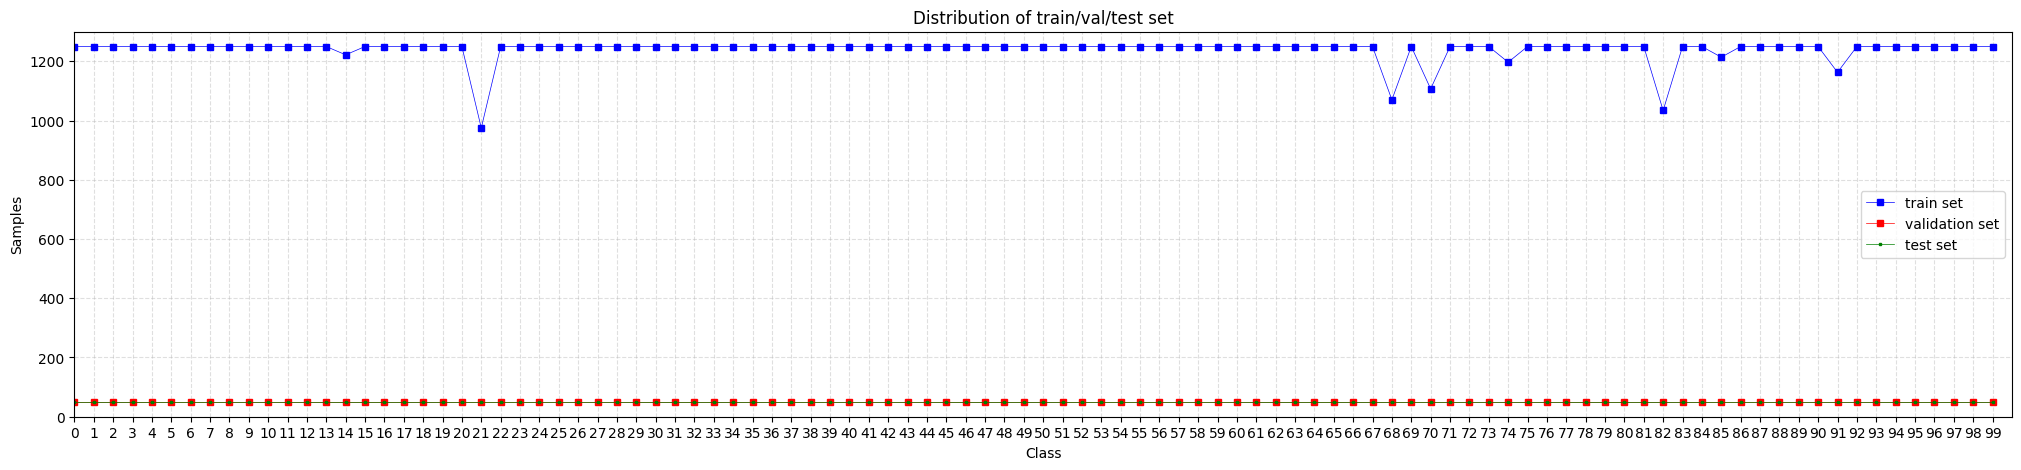

In [44]:
import matplotlib.pyplot as plt

x = df_dataset["ID"]
y_train = df_dataset["train"]
y_val = df_dataset["val"]
y_test = df_dataset["test"]

plt.figure(figsize=(25,5))
plt.plot(x, y_train, color="blue", marker='s',markersize = 4, linewidth=0.5, label="train set")
plt.plot(x, y_val, color="red", marker='s', markersize = 4, linewidth=0.5, label="validation set")
plt.plot(x, y_test, color="green", marker='s', markersize = 2, linewidth=0.5, label="test set")

plt.grid(True, axis="both", linestyle="--", alpha=0.4)
plt.xlabel('Class')
plt.ylabel('Samples')
plt.xlim(0,100)
plt.xticks(range(0,100,1))
plt.ylim(0,1300)
plt.title('Distribution of train/val/test set')
plt.legend()
plt.savefig("./data/imagenet100/data_summary.png",dpi=300, bbox_inches="tight")
plt.show()

In [45]:
total_img = df_dataset['Total'].sum()
print("Total image = ", total_img)

total_cls = df_dataset['ID'].nunique()
print("Total classes = ", total_cls)

Total image =  133982
Total classes =  100


### Data preprocessing

Fine-tune

In [ ]:
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

dataset_train_rn50_ft = ImageFolder(datapath_train, transform=rn50_ft_tf_train)
dataloader_train_rn50_ft = DataLoader(dataset_train_rn50_ft, batch_size=batch_size_a1, shuffle=True, num_workers=4, pin_memory=True, drop_last=True)

dataset_val_rn50_ft = ImageFolder(datapath_val, transform=rn50_ft_tf_test)
dataloader_val_rn50_ft = DataLoader(dataset_val_rn50_ft, batch_size=batch_size_a1, shuffle=False, num_workers=4, pin_memory=True, drop_last=False)

dataset_test_rn50_ft = ImageFolder(datapath_test, transform=rn50_ft_tf_test)
dataloader_test_rn50_ft = DataLoader(dataset_test_rn50_ft, batch_size=batch_size_a1, shuffle=False, num_workers=4, pin_memory=True, drop_last=False)

In [47]:
if (clsdict2id == dataset_train_rn50_ft.class_to_idx):
    print("Class dictionary matches the training dataset class_to_idx.")
else:
    print("Class dictionary does not match the training dataset class_to_idx.")

Class dictionary matches the training dataset class_to_idx.


In [48]:
for i, t in enumerate(dataloader_train_rn50_ft):
    print(i, t)
    break

0 [tensor([[[[-0.7822, -0.7308, -0.7479,  ..., -1.3644, -1.2103, -1.2445],
          [-0.7650, -0.7479, -0.8164,  ..., -1.4672, -1.3987, -1.5014],
          [-0.9705, -0.9877, -1.0904,  ..., -1.3130, -1.2788, -1.4158],
          ...,
          [-0.9534, -0.9363, -0.8335,  ..., -0.9877, -1.1589, -1.1760],
          [-0.6281, -0.8164, -0.6965,  ..., -1.2617, -1.2103, -1.2788],
          [-0.2342, -0.1657, -0.4739,  ..., -1.5014, -1.1589, -1.2617]],

         [[-0.4601, -0.4076, -0.4076,  ..., -1.1954, -1.0203, -0.9678],
          [-0.4601, -0.4426, -0.5126,  ..., -1.3004, -1.1954, -1.2654],
          [-0.6702, -0.7052, -0.7752,  ..., -1.1954, -1.1078, -1.2129],
          ...,
          [-1.0203, -0.9503, -0.7752,  ..., -0.8803, -1.0553, -1.0553],
          [-0.7227, -0.8627, -0.6527,  ..., -1.1604, -1.0903, -1.1604],
          [-0.3550, -0.1975, -0.4426,  ..., -1.3704, -1.0203, -1.1078]],

         [[-0.9853, -0.9504, -1.0376,  ..., -1.2467, -1.0898, -1.1073],
          [-0.9330, -0.9156

In [49]:
from torch.utils.data import DataLoader

dataset_train_vitb16_ft = ImageFolder(datapath_train, transform=vitb16_ft_tf)
dataloader_train_vitb16_ft = DataLoader(dataset_train_vitb16_ft, batch_size=batch_size_a1, shuffle=True, num_workers=4, pin_memory=True)

dataset_val_vitb16_ft = ImageFolder(datapath_val, transform=vitb16_ft_tf)
dataloader_val_vitb16_ft = DataLoader(dataset_val_vitb16_ft, batch_size=batch_size_a1, shuffle=False, num_workers=4, pin_memory=True)

dataset_test_vitb16_ft = ImageFolder(datapath_test, transform=vitb16_ft_tf)
dataloader_test_vitb16_ft = DataLoader(dataset_test_vitb16_ft, batch_size=batch_size_a1, shuffle=False, num_workers=4, pin_memory=True)

In [50]:
# show sample of dataloader in each dataset

img1, tgt1 = next(iter(dataloader_train_rn50_ft))
img2, tgt2 = next(iter(dataloader_val_rn50_ft))
img3, tgt3 = next(iter(dataloader_test_rn50_ft))
img4, tgt4 = next(iter(dataloader_train_vitb16_ft))
img5, tgt5 = next(iter(dataloader_val_vitb16_ft))
img6, tgt6 = next(iter(dataloader_test_vitb16_ft))

print(f"Input shape: {img1[0].shape}, Target class: {tgt1[0]}")
print(f"Input shape: {img2[0].shape}, Target class: {tgt2[0]}")
print(f"Input shape: {img3[0].shape}, Target class: {tgt3[0]}")
print(f"Input shape: {img4[0].shape}, Target class: {tgt4[0]}")
print(f"Input shape: {img5[0].shape}, Target class: {tgt5[0]}")
print(f"Input shape: {img6[0].shape}, Target class: {tgt6[0]}")

Input shape: torch.Size([3, 224, 224]), Target class: 41
Input shape: torch.Size([3, 224, 224]), Target class: 0
Input shape: torch.Size([3, 224, 224]), Target class: 0
Input shape: torch.Size([3, 224, 224]), Target class: 58
Input shape: torch.Size([3, 224, 224]), Target class: 0
Input shape: torch.Size([3, 224, 224]), Target class: 0


### Visualize dataset

Image tensor = torch.Size([3, 502, 800]), image shape = torch.Size([502, 800, 3]), image label = radio, wireless


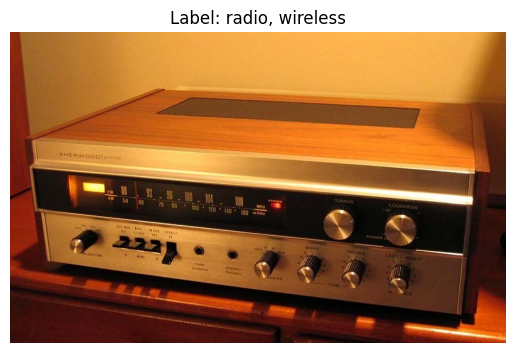

tensor([[0.1882, 0.1725, 0.1647,  ..., 0.3412, 0.3373, 0.3373],
        [0.1843, 0.1686, 0.1608,  ..., 0.3412, 0.3373, 0.3373],
        [0.1765, 0.1647, 0.1529,  ..., 0.3373, 0.3373, 0.3373],
        ...,
        [0.0627, 0.0627, 0.0588,  ..., 0.2706, 0.2784, 0.2902],
        [0.0588, 0.0588, 0.0588,  ..., 0.2706, 0.2588, 0.2627],
        [0.0588, 0.0588, 0.0588,  ..., 0.2078, 0.2078, 0.2196]])

In [51]:
# original dataset sample visualization

dataset_sample = ImageFolderDataset(datapath_train, clsdict2id=clsdict2id)
sample_image, sample_image_tf, sample_label = dataset_sample[93399]

helper_show_image(img_tensor=sample_image_tf, img_label=id2clsname[sample_label])
sample_image_tf[1][:][:]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8267832..2.4285715].


Image tensor = torch.Size([3, 224, 224]), image shape = torch.Size([224, 224, 3]), image label = radio, wireless


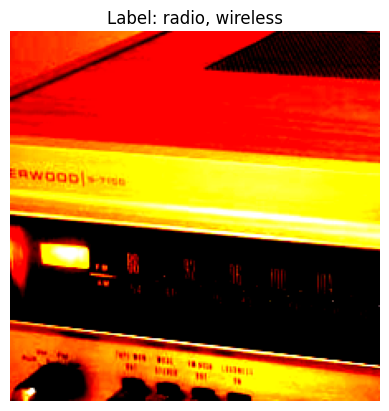

tensor([[ 0.0826,  0.0826,  0.0826,  ..., -0.5301, -0.5126, -0.4426],
        [ 0.0826,  0.0826,  0.0651,  ..., -1.1078, -1.0728, -1.1253],
        [ 0.0826,  0.0651,  0.0651,  ..., -0.6527, -0.6001, -0.7052],
        ...,
        [-0.0749, -0.4251, -0.4076,  ...,  0.3978,  0.4503,  0.3452],
        [-0.2150, -0.5126, -0.4601,  ...,  0.3803,  0.3978,  0.2927],
        [-0.4251, -0.6702, -0.6001,  ...,  0.3277,  0.3452,  0.3277]])

In [ ]:
# processing for fine-tuning dataset visualization

dataset_sample = ImageFolderDataset(datapath_train, clsdict2id=clsdict2id, transform=rn50_ft_tf_train)
sample_image, sample_image_tf, sample_label = dataset_sample[93399]

helper_show_image(img_tensor=sample_image_tf, img_label=id2clsname[sample_label])
sample_image_tf[1][:][:]

## Global Optimizer/Scheduler/Loss function

### Optimizer

SGD (Stochastic Gradient Descent)

In [53]:
class modelOpt_SGD():    
    def __init__(self, model, lr_bb=0.0001, lr_head=0.001, mm=0.9, weight_decay=0.001, model_type="resnet"):
        self.model = model
        self.lr_bb = lr_bb
        self.lr_head = lr_head
        self.mm = mm
        self.weight_decay = weight_decay

        if model_type == "resnet":
            head_params = list(map(id, self.model.fc.parameters())) # head parameters (layer fc in final layer)
        elif model_type == "vit":
            head_params = list(map(id, self.model.heads.head.parameters())) # head parameters (layer heads.head in final layer)
        
        backbone_params = [p for p in self.model.parameters() if id(p) not in head_params] # backbone parameters (all except the final layer)

        self.optimizer = torch.optim.SGD([
            {'params': backbone_params, 'lr': self.lr_bb},
            {'params': self.model.fc.parameters(), 'lr': self.lr_head} if model_type == "resnet" else {'params': self.model.heads.head.parameters(), 'lr': self.lr_head}
        ], momentum=self.mm, weight_decay=self.weight_decay)
        
    def zero_grad(self):
        self.optimizer.zero_grad(set_to_none=True)

    def step(self):
        self.optimizer.step()

    def get_lr(self):
            return {
                'lr_bb': self.optimizer.param_groups[0]['lr'],
                'lr_head': self.optimizer.param_groups[1]['lr']
            }

Adam (Adaptive Moment Estimation)

In [54]:
class modelOpt_ADAM():    
    def __init__(self, model, lr_bb=0.0001, lr_head=0.001,weight_decay=0.001, betas=(0.9, 0.999), eps=1e-8, model_type="resnet"):
        self.model = model
        self.lr_bb = lr_bb
        self.lr_head = lr_head
        self.weight_decay = weight_decay
        self.betas = betas
        self.eps = eps

        if model_type == "resnet":
            head_params = list(map(id, self.model.fc.parameters())) # head parameters (layer fc in final layer)
        elif model_type == "vit":
            head_params = list(map(id, self.model.heads.head.parameters())) # head parameters (layer heads.head in final layer)
        
        backbone_params = [p for p in self.model.parameters() if id(p) not in head_params] # backbone parameters (all except the final layer)

        self.optimizer = torch.optim.Adam(
            [
                {'params': backbone_params, 'lr': self.lr_bb},
                {'params': self.model.fc.parameters(), 'lr': self.lr_head} if model_type == "resnet" else {'params': self.model.heads.head.parameters(), 'lr': self.lr_head}
            ],
            weight_decay=self.weight_decay,
            betas=self.betas,
            eps=self.eps)
                
    def zero_grad(self):
        self.optimizer.zero_grad(set_to_none=True)

    def step(self):
        self.optimizer.step()

    def get_lr(self):
            return {
                'lr_bb': self.optimizer.param_groups[0]['lr'],
                'lr_head': self.optimizer.param_groups[1]['lr']
            }

### Scheduler

In [55]:
class modelScheduler_StepLR():
    def __init__(self, optimizer, step_size=10, gamma=0.1):
        self.optimizer = optimizer
        self.step_size = step_size
        self.gamma = gamma
        self.scheduler = torch.optim.lr_scheduler.StepLR(self.optimizer, step_size=self.step_size, gamma=self.gamma)

    def scheduler_step(self):
        self.scheduler.step()

In [56]:
class modelScheduler_CosineLR():
    def __init__(self, optimizer, T_max=50, eta_min=0):
        self.optimizer = optimizer
        self.T_max = T_max
        self.eta_min = eta_min
        self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=self.T_max, eta_min=self.eta_min)
        
    def scheduler_step(self):
        self.scheduler.step()

### Loss function

Use cross entropy for classification

In [57]:
class modelLossFunction_CE(nn.Module):
    def __init__(self):
        super(modelLossFunction_CE, self).__init__()
        self.criterion = nn.CrossEntropyLoss()

    def forward(self, outputs, targets):
        return self.criterion(outputs, targets)

## MODEL PREPARARTION

Same Dataset & Augmentation: Fixed data splits and preprocessing to isolate model performance from data-driven bias

Same Linear Head Design: A single linear layer across all backbones removes head complexity, measuring raw feature quality fairly across CNNs and Transformers

Pretrained vs. From-Scratch Comparison: Evaluates the impact of ImageNet weight initialization against learning representations from scratch

Purpose: To conduct a fair, scientific benchmark that directly compares architecture families and fine-tuning/freezing strategies under strictly controlled conditions

### PRETRAINED MODEL

In [58]:
import torchvision.models as models
from torchinfo import summary

rn50_pt_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

helper_display_model_info(rn50_pt_model)

for name, module in rn50_pt_model.named_children():
    print(f"Variable naming: self.{name:<15} | Layer type: {module.__class__.__name__}")

=============== Model layer ===============
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [59]:
import torchvision.models as models
from torchinfo import summary

vitb16_pt_model = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

helper_display_model_info(vitb16_pt_model)

for name, module in vitb16_pt_model.named_children():
    print(f"Variable naming: self.{name:<15} | Layer type: {module.__class__.__name__}")

=============== Model layer ===============
VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-

### HEAD CLASSIFIER

Define 2 head classifier

    - Basic: backbone -> linear -> output
    
    - Customer: backbone -> linear -> ReLU -> dropout -> linear -> output

In [60]:
import torch.nn as nn

def custom_head_classifier(in_features, out_classes, dropout=0):
    return nn.Sequential(
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(512, out_classes)
    )

def basic_head_classifier(in_features, out_classes):
    return nn.Sequential(
        nn.Linear(in_features, out_classes)
    )

### Evaluation method

In [ ]:
from torchmetrics.classification import Accuracy, ConfusionMatrix

global_eva_acc = Accuracy(task="multiclass", num_classes=total_cls).to(device)
rn50_pt_fb_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)
rn50_pt_ft_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)
rn50_pt_fp_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)
rn50_fs_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)
vitb16_pt_fb_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)
vitb16_pt_ft_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)
vitb16_pt_fp_cm = ConfusionMatrix(task="multiclass", num_classes=total_cls).to(device)

## [1] RESNET-50 / PRETRAINED / FREEZE FULL BACKBONE

Pretrained : resnet-50

Freeze backbone level : full freeze

Head detection : basic

### [R] [FB] Create model

#### [R] [FB] Prepare data for train/resume

In [63]:
if model_infor_rn50_pt_fb['train_type'] == 'new':
    helper_replace2json(model_infor_rn50_pt_fb['json_path'], 'infor', model_infor_rn50_pt_fb)
    helper_replace2json(model_infor_rn50_pt_fb['json_path'], 'history', history_rn50_pt_fb)
    helper_replace2json(model_infor_rn50_pt_fb['json_path'], 'result', result_rn50_pt_fb)
elif model_infor_rn50_pt_fb['train_type'] == 'resume':
    history_rn50_pt_fb = helper_get_value_json(model_infor_rn50_pt_fb['json_path'], 'history')
    result_rn50_pt_fb = helper_get_value_json(model_infor_rn50_pt_fb['json_path'], 'result')

#### [R] [FB] Backbone and head

In [64]:
from torchvision import models

# load backbone
model_rn50_pt_fb = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_pt_fb = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# display base model
print("[BASE] Resnet 50")
helper_display_model_info(model_rn50_pt_fb)

# freeze full
if model_infor_rn50_pt_fb['fine-tune'] == 'freezefull':
    for param in model_rn50_pt_fb.parameters():
        param.requires_grad = False

# replace head classifier
model_rn50_pt_fb.fc = basic_head_classifier(model_rn50_pt_fb.fc.in_features, total_cls)
model_best_rn50_pt_fb.fc = basic_head_classifier(model_best_rn50_pt_fb.fc.in_features, total_cls)

# to device
model_rn50_pt_fb = model_rn50_pt_fb.to(device)
model_best_rn50_pt_fb = model_best_rn50_pt_fb.to(device)

print("[1] Pretrained model Resnet 50 with freeze full backbone")
helper_display_model_info(model_rn50_pt_fb)

# update model information
if model_infor_rn50_pt_fb['train_type'] == 'new':
    result_rn50_pt_fb['total_params'] = sum(p.numel() for p in model_rn50_pt_fb.parameters())
    result_rn50_pt_fb['trainable_params'] = sum(p.numel() for p in model_rn50_pt_fb.parameters() if p.requires_grad)
    helper_replace2json(model_infor_rn50_pt_fb['json_path'], 'result', result_rn50_pt_fb)
elif model_infor_rn50_pt_fb['train_type'] == 'resume':
    print("[INFO] Resuming training for Resnet 50 with resume path = ", model_infor_rn50_pt_fb['resume_path'])

[BASE] Resnet 50
=============== Model layer ===============
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(

#### [R] [FB] Optimizer/Scheduler/LossFunction

In [65]:
model_rn50_pt_fb_loss_func = modelLossFunction_CE()
if model_infor_rn50_pt_fb['opt'] == 'adam':
    model_rn50_pt_fb_opt = modelOpt_ADAM(model_rn50_pt_fb, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1)
    print("Using Adam optimizer")
elif model_infor_rn50_pt_fb['opt'] == 'sgd':
    model_rn50_pt_fb_opt = modelOpt_SGD(model_rn50_pt_fb, lr_bb)
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_rn50_pt_fb['opt']}")

if model_infor_rn50_pt_fb['scheduler'] == 'step':
    model_rn50_pt_fb_scheduler = modelScheduler_StepLR(model_rn50_pt_fb_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_rn50_pt_fb['scheduler'] == 'cosine':
    if model_infor_rn50_pt_fb['train-type'] == 'new':
        T_max = model_infor_rn50_pt_fb['epoch']
    elif model_infor_rn50_pt_fb['train-type'] == 'resume':
        T_max = model_infor_rn50_pt_fb['epoch'] + model_infor_rn50_pt_fb['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_rn50_pt_fb['train-type']}")
    model_rn50_pt_fb_scheduler = modelScheduler_CosineLR(model_rn50_pt_fb_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_rn50_pt_fb['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [R] [FB] Training loop

#### [R] [FB] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [R] [FB] Start new training

In [66]:
import torch
import os
import time

if model_infor_rn50_pt_fb["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_rn50_pt_fb_loss_train_min = 0.0
    global_rn50_pt_fb_loss_val_min = 0.0
    global_rn50_pt_fb_best_val_acc = 0.0

    # loop over epochs with
    ## model_rn50_pt_fb.train() : set the model to training mode
    ## model_rn50_pt_fb.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_rn50_pt_fb["epoch_new"]):
        # training phase
        model_rn50_pt_fb.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_rn50_pt_fb(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_rn50_pt_fb_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_rn50_pt_fb_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_rn50_pt_fb_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_rn50_pt_fb_loss_train_min or global_rn50_pt_fb_loss_train_min == 0.0:
            global_rn50_pt_fb_loss_train_min = train_loss_epoch
        
        # validation phase
        model_rn50_pt_fb.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_rn50_pt_fb(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_rn50_pt_fb_loss_val_min or global_rn50_pt_fb_loss_val_min == 0.0:
            global_rn50_pt_fb_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save history
        history_rn50_pt_fb["train_loss"].append(train_loss_epoch)
        history_rn50_pt_fb["train_acc"].append(train_acc_epoch)
        history_rn50_pt_fb["val_loss"].append(val_loss_epoch)
        history_rn50_pt_fb["val_acc"].append(val_acc_epoch)
        history_rn50_pt_fb['epoch'].append(epoch + 1)
        history_rn50_pt_fb['lr_bb'].append(model_rn50_pt_fb_opt.get_lr()['lr_bb'])
        history_rn50_pt_fb['lr_head'].append(model_rn50_pt_fb_opt.get_lr()['lr_head'])

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_rn50_pt_fb_best_val_acc:
            global_rn50_pt_fb_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_pt_fb.state_dict(),
                'optimizer_state_dict': model_rn50_pt_fb_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_pt_fb_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_rn50_pt_fb_loss_train_min,
                'best_val_acc' : global_rn50_pt_fb_best_val_acc,
                'history' : history_rn50_pt_fb
            }
            torch.save(best_checkpoint, "./models/best_rn50_pt_fb_model.pth")
            print(f"Saved new best model with val_acc = {global_rn50_pt_fb_best_val_acc:.2f}%")

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_rn50_pt_fb.state_dict(),
            'optimizer_state_dict': model_rn50_pt_fb_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_rn50_pt_fb_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_rn50_pt_fb_loss_train_min,
            'best_val_acc' : global_rn50_pt_fb_best_val_acc,
            'history' : history_rn50_pt_fb
        }
        torch.save(last_checkpoint, "./models/last_rn50_pt_fb_model.pth")

    end_train_time = time.time()
    result_rn50_pt_fb['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

Start new training from epoch 0, all history will be store from the beginning
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 1801/1937
Done batch 1901/1937
[epoch = 0] [train_loss = 0.7408] [train_acc = 86.57%] [val_loss = 0.5510] [val_acc = 87.36%]
Saved new best model with val_acc = 87.36%
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 

#### [R] [FB] Resume training

In [67]:
import os
import torch

if model_infor_rn50_pt_fb["train_type"] == "resume":
    if model_infor_rn50_pt_fb['resume_path'] is not None:
        last_checkpoint_path = model_infor_rn50_pt_fb['resume_path']

        if not os.path.exists(last_checkpoint_path):
            raise FileNotFoundError(f"Checkpoint file not found at {last_checkpoint_path}")
        else:
            cont_epoch = 0
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_rn50_pt_fb.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_rn50_pt_fb_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_rn50_pt_fb_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_rn50_pt_fb = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_rn50_pt_fb_loss_train_min = checkpoint['min_train_loss']
            global_rn50_pt_fb_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


In [68]:
import time

if model_infor_rn50_pt_fb["train_type"] == "resume":
    if model_infor_rn50_pt_fb['resume_path'] is not None:
        
        start_time = time.time()
        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_rn50_pt_fb["epoch_resume"]):
            model_rn50_pt_fb.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_rn50_pt_fb(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_rn50_pt_fb_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_rn50_pt_fb_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_rn50_pt_fb_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_rn50_pt_fb_loss_train_min or global_rn50_pt_fb_loss_train_min == 0.0:
                global_rn50_pt_fb_loss_train_min = train_loss_epoch
            
            # validation phase
            model_rn50_pt_fb.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_rn50_pt_fb(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_rn50_pt_fb_loss_val_min or global_rn50_pt_fb_loss_val_min == 0.0:
                global_rn50_pt_fb_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_rn50_pt_fb_best_val_acc:
                global_rn50_pt_fb_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_rn50_pt_fb.state_dict(),
                    'optimizer_state_dict': model_rn50_pt_fb_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_rn50_pt_fb_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_rn50_pt_fb_loss_train_min,
                    'best_val_acc': global_rn50_pt_fb_best_val_acc,
                    'history' : history_rn50_pt_fb
                }
                torch.save(best_checkpoint, "./models/best_rn50_pt_fb_model.pth")
                print(f"Saved new best model with val_acc = {global_rn50_pt_fb_best_val_acc:.2f}%")

            # save history
            history_rn50_pt_fb["train_loss"].append(train_loss_epoch)
            history_rn50_pt_fb["train_acc"].append(train_acc_epoch)
            history_rn50_pt_fb["val_loss"].append(val_loss_epoch)
            history_rn50_pt_fb["val_acc"].append(val_acc_epoch)
            history_rn50_pt_fb['epoch'].append(epoch + 1)
            history_rn50_pt_fb['lr_bb'].append(model_rn50_pt_fb_opt.get_lr()['lr_bb'])
            history_rn50_pt_fb['lr_head'].append(model_rn50_pt_fb_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_pt_fb.state_dict(),
                'optimizer_state_dict': model_rn50_pt_fb_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_pt_fb_scheduler.scheduler.state_dict(),
                'min_train_loss': global_rn50_pt_fb_loss_train_min,
                'best_val_acc': global_rn50_pt_fb_best_val_acc,
                'history' : history_rn50_pt_fb
            }
            torch.save(last_checkpoint, f'./models/last_rn50_pt_fb_model_from_{cont_epoch}.pth')

        end_train_time = time.time()
        result_rn50_pt_fb['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


### [R] [FB] Executing testing

Testing with best model which return maximum accuracy from validation set

In [276]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_rn50_pt_fb_model.pth", map_location=device)

# load weights
model_best_rn50_pt_fb.load_state_dict(checkpoint['model_state_dict'])

model_best_rn50_pt_fb.to(device)
model_best_rn50_pt_fb.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\556129010.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_rn50_pt_fb_model.pth"

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_rn50_pt_fb(inputs) # input => Resnet50 => output logits z

        test_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_rn50_pt_fb['test_time'] = end_test_time - start_time
result_rn50_pt_fb['test_loss'] = test_loss_total / test_sample_total
result_rn50_pt_fb['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100

test_preds = torch.cat(test_preds)
act_preds = torch.cat(act_preds)

rn50_pt_fb_cm.reset()
rn50_pt_fb_cm.update(test_preds, act_preds)

print(f"[test_loss = {result_rn50_pt_fb['test_loss']:.4f}] [test_acc = {result_rn50_pt_fb['test_acc']:.2f}%]")

[test_loss = 0.3356] [test_acc = 91.76%]


### [R] [FB] Evaluation

Loss/Accuracy of training/validation set

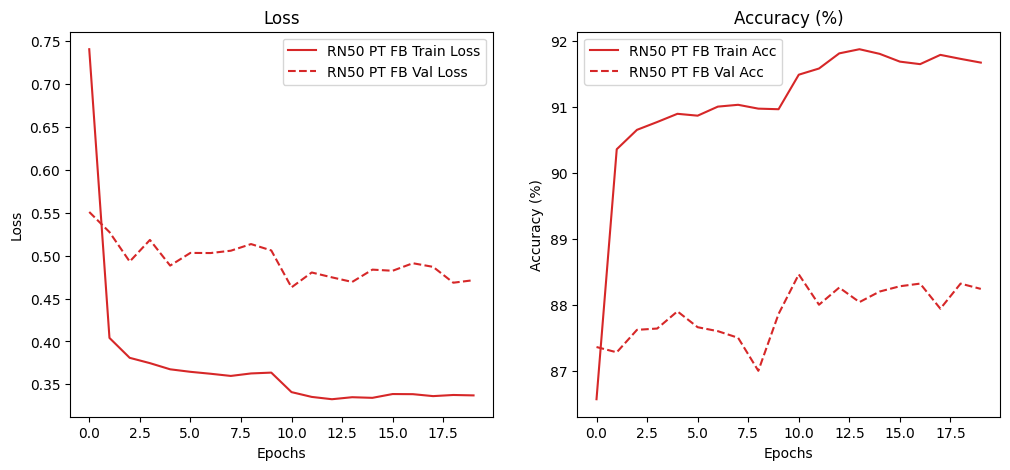

In [71]:
helper_plot_curves([history_rn50_pt_fb], ["RN50 PT FB"])

Summary model performance

In [303]:
helper_summary_performance(result_rn50_pt_fb, history_rn50_pt_fb)

Test Performance:
Test Accuracy: 91.75999450683594
Test Loss: 0.33562515745162963
Min loss of training set = 0.33260388350403675
Min loss of validation set = 0.46309385887384413
Max accuracy of training set = 91.86806272586475
Max accuracy of validation set = 88.46000000000001
Train time = 65:12
Test time = 0:22


TP FP TN FN

In [304]:
import pandas as pd

helper_extract_tp_tn_fp_fn([rn50_pt_fb_cm], [result_rn50_pt_fb])

result_rn50_pt_fb

Accuracy: 0.917600
Macro Recall: 0.917600
Difference: 0.0000000596


{'test_acc': tensor(91.7600, device='cuda:0'),
 'test_loss': 0.33562515745162963,
 'train_time': 3912.82554602623,
 'test_time': 22.143109798431396,
 'tp': tensor([46., 46., 46., 44., 42., 47., 48., 46., 50., 48., 47., 47., 49., 47.,
         48., 44., 45., 46., 49., 46., 43., 45., 45., 45., 47., 47., 41., 47.,
         49., 47., 44., 45., 49., 47., 47., 46., 48., 47., 44., 50., 49., 47.,
         43., 48., 46., 46., 45., 49., 44., 48., 44., 45., 45., 42., 40., 49.,
         45., 46., 48., 45., 43., 38., 44., 43., 40., 46., 47., 48., 44., 43.,
         44., 46., 45., 38., 42., 46., 46., 47., 43., 49., 45., 48., 47., 45.,
         46., 49., 48., 44., 45., 47., 47., 47., 41., 48., 48., 50., 47., 47.,
         50., 49.]),
 'tn': tensor([4949., 4947., 4947., 4947., 4944., 4947., 4943., 4949., 4943., 4949.,
         4950., 4950., 4949., 4946., 4943., 4949., 4947., 4950., 4949., 4946.,
         4948., 4947., 4947., 4947., 4946., 4945., 4949., 4946., 4948., 4948.,
         4946., 4942., 4945.

Save testing result

In [305]:
helper_replace2json(model_infor_rn50_pt_fb['json_path'], 'result', clean_for_json(result_rn50_pt_fb))
helper_replace2json(model_infor_rn50_pt_fb['json_path'], 'history', clean_for_json(history_rn50_pt_fb))

## [2] RESNET-50 / PRETRAINED / PARTIAL FINE-TUNE

Pretrained : resnet-50

Freeze backbone level : partial fine-tune

Head detection : basic

### [R] [FP] Create model

#### [R] [FP] Prepare data for train/resume

In [76]:
if model_infor_rn50_pt_fp['train_type'] == 'new':
    helper_replace2json(model_infor_rn50_pt_fp['json_path'], 'infor', model_infor_rn50_pt_fp)
    helper_replace2json(model_infor_rn50_pt_fp['json_path'], 'history', history_rn50_pt_fp)
    helper_replace2json(model_infor_rn50_pt_fp['json_path'], 'result', result_rn50_pt_fp)
elif model_infor_rn50_pt_fp['train_type'] == 'resume':
    history_rn50_pt_fp = helper_get_value_json(model_infor_rn50_pt_fp['json_path'], 'history')
    result_rn50_pt_fp = helper_get_value_json(model_infor_rn50_pt_fp['json_path'], 'result')

#### [R] [FP] Backbone and head

In [77]:
from torchvision import models

# load backbone
model_rn50_pt_fp = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_pt_fp = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# display base model
print("[BASE] Resnet 50")
helper_display_model_info(model_rn50_pt_fp)

# freeze full
if model_infor_rn50_pt_fp['fine-tune'] == 'freezefull':
    for param in model_rn50_pt_fp.parameters():
        param.requires_grad = False
elif model_infor_rn50_pt_fp['fine-tune'] == 'partial':
    for param in model_rn50_pt_fp.parameters(): # freeze all params
        param.requires_grad = False

    for param in model_rn50_pt_fp.layer4.parameters(): # fine-tune layer4
        param.requires_grad = True
    
    for param in model_rn50_pt_fp.fc.parameters(): # fine-tune FC layer
        param.requires_grad = True
else:
    # Do nothing
    pass

# replace head classifier
model_rn50_pt_fp.fc = basic_head_classifier(model_rn50_pt_fp.fc.in_features, total_cls)
model_best_rn50_pt_fp.fc = basic_head_classifier(model_best_rn50_pt_fp.fc.in_features, total_cls)

# to device
model_rn50_pt_fp = model_rn50_pt_fp.to(device)
model_best_rn50_pt_fp = model_best_rn50_pt_fp.to(device)

print("[1] Pretrained model Resnet 50 with freeze full backbone")
helper_display_model_info(model_rn50_pt_fp)

# update model information
if model_infor_rn50_pt_fp['train_type'] == 'new':
    result_rn50_pt_fp['total_params'] = sum(p.numel() for p in model_rn50_pt_fp.parameters())
    result_rn50_pt_fp['trainable_params'] = sum(p.numel() for p in model_rn50_pt_fp.parameters() if p.requires_grad)
    helper_replace2json(model_infor_rn50_pt_fp['json_path'], 'result', result_rn50_pt_fp)
elif model_infor_rn50_pt_fp['train_type'] == 'resume':
    print("[INFO] Resuming training for Resnet 50 with resume path = ", model_infor_rn50_pt_fp['resume_path'])

[BASE] Resnet 50
=============== Model layer ===============
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(

#### [R] [FP] Optimizer/Scheduler/LossFunction

In [78]:
model_rn50_pt_fp_loss_func = modelLossFunction_CE()
if model_infor_rn50_pt_fp['opt'] == 'adam':
    model_rn50_pt_fp_opt = modelOpt_ADAM(model_rn50_pt_fp, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1)
    print("Using Adam optimizer")
elif model_infor_rn50_pt_fp['opt'] == 'sgd':
    model_rn50_pt_fp_opt = modelOpt_SGD(model_rn50_pt_fp, lr_bb)
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_rn50_pt_fp['opt']}")

if model_infor_rn50_pt_fp['scheduler'] == 'step':
    model_rn50_pt_fp_scheduler = modelScheduler_StepLR(model_rn50_pt_fp_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_rn50_pt_fp['scheduler'] == 'cosine':
    if model_infor_rn50_pt_fp['train-type'] == 'new':
        T_max = model_infor_rn50_pt_fp['epoch']
    elif model_infor_rn50_pt_fp['train-type'] == 'resume':
        T_max = model_infor_rn50_pt_fp['epoch'] + model_infor_rn50_pt_fp['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_rn50_pt_fp['train-type']}")
    model_rn50_pt_fp_scheduler = modelScheduler_CosineLR(model_rn50_pt_fp_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_rn50_pt_fp['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [R] [FP] Training loop

#### [R] [FP] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [R] [FP] Start new training

In [80]:
import torch
import os
import time

if model_infor_rn50_pt_fp["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_rn50_pt_fp_loss_train_min = 0.0
    global_rn50_pt_fp_loss_val_min = 0.0
    global_rn50_pt_fp_best_val_acc = 0.0

    # loop over epochs with
    ## model_rn50_pt_fp.train() : set the model to training mode
    ## model_rn50_pt_fp.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_rn50_pt_fp["epoch_new"]):
        # training phase
        model_rn50_pt_fp.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_rn50_pt_fp(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_rn50_pt_fp_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_rn50_pt_fp_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_rn50_pt_fp_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_rn50_pt_fp_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_rn50_pt_fp_loss_train_min or global_rn50_pt_fp_loss_train_min == 0.0:
            global_rn50_pt_fp_loss_train_min = train_loss_epoch
        
        # validation phase
        model_rn50_pt_fp.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_rn50_pt_fp(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_rn50_pt_fp_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_rn50_pt_fp_loss_val_min or global_rn50_pt_fp_loss_val_min == 0.0:
            global_rn50_pt_fp_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save history
        history_rn50_pt_fp["train_loss"].append(train_loss_epoch)
        history_rn50_pt_fp["train_acc"].append(train_acc_epoch)
        history_rn50_pt_fp["val_loss"].append(val_loss_epoch)
        history_rn50_pt_fp["val_acc"].append(val_acc_epoch)
        history_rn50_pt_fp['epoch'].append(epoch + 1)
        history_rn50_pt_fp['lr_bb'].append(model_rn50_pt_fp_opt.get_lr()['lr_bb'])
        history_rn50_pt_fp['lr_head'].append(model_rn50_pt_fp_opt.get_lr()['lr_head'])

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_rn50_pt_fp_best_val_acc:
            global_rn50_pt_fp_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_pt_fp.state_dict(),
                'optimizer_state_dict': model_rn50_pt_fp_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_pt_fp_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_rn50_pt_fp_loss_train_min,
                'best_val_acc' : global_rn50_pt_fp_best_val_acc,
                'history' : history_rn50_pt_fp
            }
            torch.save(best_checkpoint, "./models/best_rn50_pt_fp_model.pth")
            print(f"Saved new best model with val_acc = {global_rn50_pt_fp_best_val_acc:.2f}%")

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_rn50_pt_fp.state_dict(),
            'optimizer_state_dict': model_rn50_pt_fp_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_rn50_pt_fp_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_rn50_pt_fp_loss_train_min,
            'best_val_acc' : global_rn50_pt_fp_best_val_acc,
            'history' : history_rn50_pt_fp
        }
        torch.save(last_checkpoint, "./models/last_rn50_pt_fp_model.pth")

    end_train_time = time.time()
    result_rn50_pt_fp['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

Start new training from epoch 0, all history will be store from the beginning
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 1801/1937
Done batch 1901/1937
[epoch = 0] [train_loss = 0.8325] [train_acc = 78.73%] [val_loss = 0.8203] [val_acc = 79.16%]
Saved new best model with val_acc = 79.16%
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 

#### [R] [FP] Resume training

In [81]:
import os
import torch

if model_infor_rn50_pt_fb["train_type"] == "resume":
    if model_infor_rn50_pt_fb['resume_path'] is not None:
        last_checkpoint_path = model_infor_rn50_pt_fb['resume_path']

        if not os.path.exists(last_checkpoint_path):
            raise FileNotFoundError(f"Checkpoint file not found at {last_checkpoint_path}")
        else:
            cont_epoch = 0
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_rn50_pt_fb.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_rn50_pt_fb_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_rn50_pt_fb_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_rn50_pt_fb = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_rn50_pt_fb_loss_train_min = checkpoint['min_train_loss']
            global_rn50_pt_fb_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


In [82]:
import time

if model_infor_rn50_pt_fb["train_type"] == "resume":
    if model_infor_rn50_pt_fb['resume_path'] is not None:
        
        start_time = time.time()
        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_rn50_pt_fb["epoch_resume"]):
            model_rn50_pt_fb.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_rn50_pt_fb(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_rn50_pt_fb_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_rn50_pt_fb_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_rn50_pt_fb_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_rn50_pt_fb_loss_train_min or global_rn50_pt_fb_loss_train_min == 0.0:
                global_rn50_pt_fb_loss_train_min = train_loss_epoch
            
            # validation phase
            model_rn50_pt_fb.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_rn50_pt_fb(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_rn50_pt_fb_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_rn50_pt_fb_loss_val_min or global_rn50_pt_fb_loss_val_min == 0.0:
                global_rn50_pt_fb_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_rn50_pt_fb_best_val_acc:
                global_rn50_pt_fb_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_rn50_pt_fb.state_dict(),
                    'optimizer_state_dict': model_rn50_pt_fb_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_rn50_pt_fb_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_rn50_pt_fb_loss_train_min,
                    'best_val_acc': global_rn50_pt_fb_best_val_acc,
                    'history' : history_rn50_pt_fb
                }
                torch.save(best_checkpoint, "./models/best_rn50_pt_fb_model.pth")
                print(f"Saved new best model with val_acc = {global_rn50_pt_fb_best_val_acc:.2f}%")

            # save history
            history_rn50_pt_fp["train_loss"].append(train_loss_epoch)
            history_rn50_pt_fp["train_acc"].append(train_acc_epoch)
            history_rn50_pt_fp["val_loss"].append(val_loss_epoch)
            history_rn50_pt_fp["val_acc"].append(val_acc_epoch)
            history_rn50_pt_fp['epoch'].append(epoch + 1)
            history_rn50_pt_fp['lr_bb'].append(model_rn50_pt_fp_opt.get_lr()['lr_bb'])
            history_rn50_pt_fp['lr_head'].append(model_rn50_pt_fp_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_pt_fb.state_dict(),
                'optimizer_state_dict': model_rn50_pt_fb_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_pt_fb_scheduler.scheduler.state_dict(),
                'min_train_loss': global_rn50_pt_fb_loss_train_min,
                'best_val_acc': global_rn50_pt_fb_best_val_acc,
                'history' : history_rn50_pt_fb
            }
            torch.save(last_checkpoint, f'./models/last_rn50_pt_fb_model_from_{cont_epoch}.pth')

        end_train_time = time.time()
        result_rn50_pt_fb['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


### [R] [FP] Executing testing

Testing with best model which return maximum accuracy from validation set

In [83]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_rn50_pt_fp_model.pth", map_location=device)

# load weights
model_best_rn50_pt_fp.load_state_dict(checkpoint['model_state_dict'])

model_best_rn50_pt_fp.to(device)
model_best_rn50_pt_fp.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\1716095554.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_rn50_pt_fp_model.pth

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [306]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_rn50_pt_fp(inputs) # input => Resnet50 => output logits z

        test_loss_mean_batch = model_rn50_pt_fp_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_rn50_pt_fp['test_time'] = end_test_time - start_time
result_rn50_pt_fp['test_loss'] = test_loss_total / test_sample_total
result_rn50_pt_fp['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100

test_preds = torch.cat(test_preds)
act_preds = torch.cat(act_preds)

rn50_pt_fp_cm.reset()
rn50_pt_fp_cm.update(test_preds, act_preds)

print(f"[test_loss = {result_rn50_pt_fp['test_loss']:.4f}] [test_acc = {result_rn50_pt_fp['test_acc']:.2f}%]")

[test_loss = 0.5159] [test_acc = 86.70%]


### [R] [FP] Evaluation

Loss/Accuracy of training/validation set

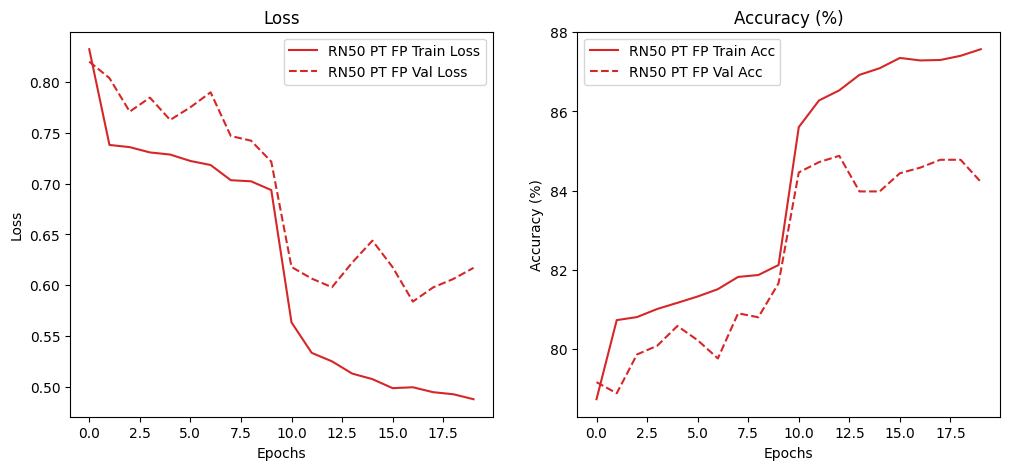

In [85]:
helper_plot_curves([history_rn50_pt_fp], ["RN50 PT FP"])

Summary model performance

In [307]:
helper_summary_performance(result_rn50_pt_fp, history_rn50_pt_fp)

Test Performance:
Test Accuracy: 86.69999694824219
Test Loss: 0.515949190723896
Min loss of training set = 0.4875565511575974
Min loss of validation set = 0.5837857180595398
Max accuracy of training set = 87.57340604026845
Max accuracy of validation set = 84.88
Train time = 67:12
Test time = 0:21


TP FP TN FN

In [308]:
helper_extract_tp_tn_fp_fn([rn50_pt_fp_cm], [result_rn50_pt_fp])

result_rn50_pt_fp

Accuracy: 0.867000
Macro Recall: 0.867000
Difference: 0.0000000596


{'test_acc': tensor(86.7000, device='cuda:0'),
 'test_loss': 0.515949190723896,
 'train_time': 4032.169049501419,
 'test_time': 21.400521993637085,
 'tp': tensor([44., 45., 44., 41., 38., 42., 45., 47., 47., 43., 47., 46., 47., 42.,
         45., 44., 44., 47., 50., 42., 38., 43., 42., 44., 46., 44., 41., 41.,
         50., 47., 47., 45., 44., 44., 44., 44., 50., 47., 43., 47., 46., 44.,
         44., 44., 43., 50., 43., 47., 46., 47., 40., 40., 43., 42., 38., 48.,
         42., 39., 43., 46., 37., 37., 43., 37., 37., 44., 47., 40., 42., 35.,
         39., 42., 43., 33., 38., 43., 40., 45., 40., 45., 37., 46., 40., 40.,
         41., 47., 43., 41., 42., 42., 47., 42., 42., 46., 44., 49., 45., 44.,
         47., 47.]),
 'tn': tensor([4946., 4949., 4948., 4946., 4941., 4946., 4946., 4947., 4940., 4948.,
         4944., 4946., 4948., 4949., 4936., 4944., 4942., 4946., 4949., 4946.,
         4945., 4942., 4949., 4947., 4946., 4942., 4947., 4944., 4948., 4937.,
         4941., 4926., 4946.,

Save testing result

In [309]:
helper_replace2json(model_infor_rn50_pt_fp['json_path'], 'result', clean_for_json(result_rn50_pt_fp))
helper_replace2json(model_infor_rn50_pt_fp['json_path'], 'history', clean_for_json(history_rn50_pt_fp))

## [3] RESNET-50 / PRETRAINED / FULL FINE-TUNE

Pretrained : resnet-50

Freeze backbone level : full fine-tune

Head detection : basic

### [R] [FT] Create model

#### [R] [FT] Prepare data for train/resume

In [89]:
if model_infor_rn50_pt_ft['train_type'] == 'new':
    helper_replace2json(model_infor_rn50_pt_ft['json_path'], 'infor', model_infor_rn50_pt_ft)
    helper_replace2json(model_infor_rn50_pt_ft['json_path'], 'history', history_rn50_pt_ft)
    helper_replace2json(model_infor_rn50_pt_ft['json_path'], 'result', result_rn50_pt_ft)
elif model_infor_rn50_pt_ft['train_type'] == 'resume':
    history_rn50_pt_ft = helper_get_value_json(model_infor_rn50_pt_ft['json_path'], 'history')
    result_rn50_pt_ft = helper_get_value_json(model_infor_rn50_pt_ft['json_path'], 'result')

#### [R] [FT] Backbone and head

In [91]:
from torchvision import models

# load backbone
model_rn50_pt_ft = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_pt_ft = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# display base model
print("[BASE] Resnet 50")
helper_display_model_info(model_rn50_pt_ft)

# freeze full
if model_infor_rn50_pt_ft['fine-tune'] == 'freezefull':
    for param in model_rn50_pt_ft.parameters():
        param.requires_grad = False

# replace head classifier
model_rn50_pt_ft.fc = basic_head_classifier(model_rn50_pt_ft.fc.in_features, total_cls)
model_best_rn50_pt_ft.fc = basic_head_classifier(model_best_rn50_pt_ft.fc.in_features, total_cls)

# to device
model_rn50_pt_ft = model_rn50_pt_ft.to(device)
model_best_rn50_pt_ft = model_best_rn50_pt_ft.to(device)

print("[1] Pretrained model Resnet 50 with freeze full backbone")
helper_display_model_info(model_rn50_pt_ft)

# update model information
if model_infor_rn50_pt_ft['train_type'] == 'new':
    result_rn50_pt_ft['total_params'] = sum(p.numel() for p in model_rn50_pt_ft.parameters())
    result_rn50_pt_ft['trainable_params'] = sum(p.numel() for p in model_rn50_pt_ft.parameters() if p.requires_grad)
    helper_replace2json(model_infor_rn50_pt_ft['json_path'], 'result', result_rn50_pt_ft)
elif model_infor_rn50_pt_ft['train_type'] == 'resume':
    print("[INFO] Resuming training for Resnet 50 with resume path = ", model_infor_rn50_pt_ft['resume_path'])

[BASE] Resnet 50
=============== Model layer ===============
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(

#### [R] [FT] Optimizer/Scheduler/LossFunction

In [92]:
model_rn50_pt_ft_loss_func = modelLossFunction_CE()
if model_infor_rn50_pt_ft['opt'] == 'adam':
    model_rn50_pt_ft_opt = modelOpt_ADAM(model_rn50_pt_ft, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1)
    print("Using Adam optimizer")
elif model_infor_rn50_pt_ft['opt'] == 'sgd':
    model_rn50_pt_ft_opt = modelOpt_SGD(model_rn50_pt_ft, lr_bb)
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_rn50_pt_ft['opt']}")

if model_infor_rn50_pt_ft['scheduler'] == 'step':
    model_rn50_pt_ft_scheduler = modelScheduler_StepLR(model_rn50_pt_ft_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_rn50_pt_ft['scheduler'] == 'cosine':
    if model_infor_rn50_pt_ft['train-type'] == 'new':
        T_max = model_infor_rn50_pt_ft['epoch']
    elif model_infor_rn50_pt_ft['train-type'] == 'resume':
        T_max = model_infor_rn50_pt_ft['epoch'] + model_infor_rn50_pt_ft['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_rn50_pt_ft['train-type']}")
    model_rn50_pt_ft_scheduler = modelScheduler_CosineLR(model_rn50_pt_ft_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_rn50_pt_ft['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [R] [FT] Training loop

#### [R] [FT] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [R] [FT] Start new training

In [93]:
import torch
import os
import time

if model_infor_rn50_pt_ft["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_rn50_pt_ft_loss_train_min = 0.0
    global_rn50_pt_ft_loss_val_min = 0.0
    global_rn50_pt_ft_best_val_acc = 0.0

    # loop over epochs with
    ## model_rn50_pt_ft.train() : set the model to training mode
    ## model_rn50_pt_ft.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_rn50_pt_ft["epoch_new"]):
        # training phase
        model_rn50_pt_ft.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_rn50_pt_ft(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_rn50_pt_ft_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_rn50_pt_ft_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_rn50_pt_ft_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_rn50_pt_ft_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_rn50_pt_ft_loss_train_min or global_rn50_pt_ft_loss_train_min == 0.0:
            global_rn50_pt_ft_loss_train_min = train_loss_epoch
        
        # validation phase
        model_rn50_pt_ft.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_rn50_pt_ft(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_rn50_pt_ft_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_rn50_pt_ft_loss_val_min or global_rn50_pt_ft_loss_val_min == 0.0:
            global_rn50_pt_ft_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_rn50_pt_ft_best_val_acc:
            global_rn50_pt_ft_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_pt_ft.state_dict(),
                'optimizer_state_dict': model_rn50_pt_ft_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_pt_ft_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_rn50_pt_ft_loss_train_min,
                'best_val_acc' : global_rn50_pt_ft_best_val_acc,
                'history': history_rn50_pt_ft
            }
            torch.save(best_checkpoint, "./models/best_rn50_pt_ft_model.pth")
            print(f"Saved new best model with val_acc = {global_rn50_pt_ft_best_val_acc:.2f}%")

        # save history
        history_rn50_pt_ft["train_loss"].append(train_loss_epoch)
        history_rn50_pt_ft["train_acc"].append(train_acc_epoch)
        history_rn50_pt_ft["val_loss"].append(val_loss_epoch)
        history_rn50_pt_ft["val_acc"].append(val_acc_epoch)
        history_rn50_pt_ft['epoch'].append(epoch + 1)
        history_rn50_pt_ft['lr_bb'].append(model_rn50_pt_ft_opt.get_lr()['lr_bb'])
        history_rn50_pt_ft['lr_head'].append(model_rn50_pt_ft_opt.get_lr()['lr_head'])

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_rn50_pt_ft.state_dict(),
            'optimizer_state_dict': model_rn50_pt_ft_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_rn50_pt_ft_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_rn50_pt_ft_loss_train_min,
            'best_val_acc' : global_rn50_pt_ft_best_val_acc,
            'history': history_rn50_pt_ft
        }
        torch.save(last_checkpoint, './models/last_rn50_pt_ft_model.pth')

    end_train_time = time.time()
    result_rn50_pt_ft['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

Start new training from epoch 0, all history will be store from the beginning
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 1801/1937
Done batch 1901/1937
[epoch = 0] [train_loss = 1.3644] [train_acc = 65.17%] [val_loss = 1.4836] [val_acc = 61.38%]
Saved new best model with val_acc = 61.38%
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 

#### [R] [FT] Resume training

In [94]:
import os
import torch
from pathlib import Path

cont_epoch = 0

if model_infor_rn50_pt_ft["train_type"] == "resume":
    if model_infor_rn50_pt_ft['resume_path'] is not None:
        last_checkpoint_path = model_infor_rn50_pt_ft['resume_path']

        if os.path.exists(Path(last_checkpoint_path)):
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_rn50_pt_ft.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_rn50_pt_ft_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_rn50_pt_ft_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_rn50_pt_ft = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_rn50_pt_ft_loss_train_min = checkpoint['min_train_loss']
            global_rn50_pt_ft_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
        else:
            print(f"Last checkpoint not found at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


In [95]:
import time

if model_infor_rn50_pt_ft["train_type"] == "resume":
    if model_infor_rn50_pt_ft['resume_path'] is not None:
        start_time = time.time()

        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_rn50_pt_ft["epoch_resume"]):
            model_rn50_pt_ft.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_rn50_pt_ft(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_rn50_pt_ft_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_rn50_pt_ft_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_rn50_pt_ft_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_rn50_pt_ft_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_rn50_pt_ft_loss_train_min or global_rn50_pt_ft_loss_train_min == 0.0:
                global_rn50_pt_ft_loss_train_min = train_loss_epoch
            
            # validation phase
            model_rn50_pt_ft.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_rn50_pt_ft(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_rn50_pt_ft_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_rn50_pt_ft_loss_val_min or global_rn50_pt_ft_loss_val_min == 0.0:
                global_rn50_pt_ft_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_rn50_pt_ft_best_val_acc:
                global_rn50_pt_ft_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_rn50_pt_ft.state_dict(),
                    'optimizer_state_dict': model_rn50_pt_ft_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_rn50_pt_ft_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_rn50_pt_ft_loss_train_min,
                    'best_val_acc': global_rn50_pt_ft_best_val_acc,
                    'history' : history_rn50_pt_ft
                }
                torch.save(best_checkpoint, "./models/best_rn50_pt_ft_model.pth")
                print(f"Saved new best model with val_acc = {global_rn50_pt_ft_best_val_acc:.2f}%")

            # save history
            history_rn50_pt_ft["train_loss"].append(train_loss_epoch)
            history_rn50_pt_ft["train_acc"].append(train_acc_epoch)
            history_rn50_pt_ft["val_loss"].append(val_loss_epoch)
            history_rn50_pt_ft["val_acc"].append(val_acc_epoch)
            history_rn50_pt_ft['epoch'].append(epoch + 1)
            history_rn50_pt_ft['lr_bb'].append(model_rn50_pt_ft_opt.get_lr()['lr_bb'])
            history_rn50_pt_ft['lr_head'].append(model_rn50_pt_ft_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_pt_ft.state_dict(),
                'optimizer_state_dict': model_rn50_pt_ft_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_pt_ft_scheduler.scheduler.state_dict(),
                'min_train_loss': global_rn50_pt_ft_loss_train_min,
                'best_val_acc': global_rn50_pt_ft_best_val_acc,
                'history' : history_rn50_pt_ft
            }
            torch.save(last_checkpoint, f'./models/last_rn50_pt_ft_model_from_{cont_epoch}.pth')
        end_train_time = time.time()
        result_rn50_pt_ft['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


### [R] [FT] Executing testing

Testing with best model which return maximum accuracy from validation set

In [96]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_rn50_pt_ft_model.pth", map_location=device)

# load weights
model_best_rn50_pt_ft.load_state_dict(checkpoint['model_state_dict'])

model_best_rn50_pt_ft.to(device)
model_best_rn50_pt_ft.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\2137877220.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_rn50_pt_ft_model.pth

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [310]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_rn50_pt_ft(inputs) # input => Resnet50 => output logits z

        test_loss_mean_batch = model_rn50_pt_ft_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_rn50_pt_ft['test_time'] = end_test_time - start_time
result_rn50_pt_ft['test_loss'] = test_loss_total / test_sample_total
result_rn50_pt_ft['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100

test_preds = torch.cat(test_preds)
act_preds = torch.cat(act_preds)

rn50_pt_ft_cm.reset()
rn50_pt_ft_cm.update(test_preds, act_preds)

print(f"[test_loss = {result_rn50_pt_ft['test_loss']:.4f}] [test_acc = {result_rn50_pt_ft['test_acc']:.2f}%]")

[test_loss = 0.9275] [test_acc = 75.74%]


### [R] [FT] Evaluation

Loss/Accuracy of training/validation set

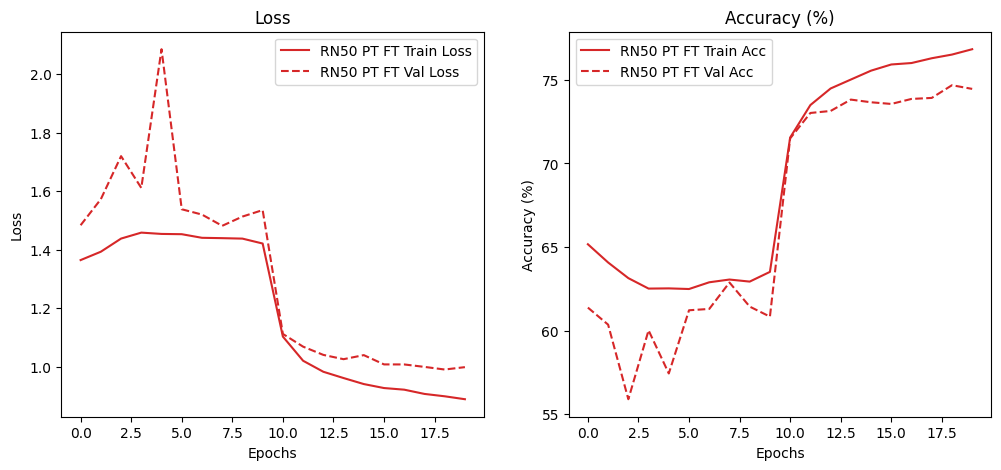

In [99]:
helper_plot_curves([history_rn50_pt_ft], ["RN50 PT FT"])

Summary model performance

In [311]:
helper_summary_performance(result_rn50_pt_ft, history_rn50_pt_ft)

Test Performance:
Test Accuracy: 75.73999786376953
Test Loss: 0.9274938473463058
Min loss of training set = 0.8884694280701935
Min loss of validation set = 0.9900585279986263
Max accuracy of training set = 76.8327310273619
Max accuracy of validation set = 74.68
Train time = 158:49
Test time = 0:21


TP FP TN FN

In [312]:
import pandas as pd

helper_extract_tp_tn_fp_fn([rn50_pt_ft_cm], [result_rn50_pt_ft])

result_rn50_pt_ft

Accuracy: 0.757400
Macro Recall: 0.757400
Difference: 0.0000000596


{'test_acc': tensor(75.7400, device='cuda:0'),
 'test_loss': 0.9274938473463058,
 'train_time': 9529.753110647202,
 'test_time': 21.551026821136475,
 'tp': tensor([32., 44., 44., 42., 33., 38., 43., 42., 42., 42., 45., 40., 47., 34.,
         35., 35., 43., 43., 49., 42., 28., 38., 26., 39., 43., 36., 37., 42.,
         40., 39., 36., 37., 38., 40., 36., 41., 47., 43., 44., 42., 40., 42.,
         34., 41., 37., 47., 43., 40., 35., 38., 31., 33., 39., 32., 26., 37.,
         42., 34., 44., 41., 35., 23., 27., 25., 26., 44., 40., 36., 33., 30.,
         28., 34., 33., 27., 30., 40., 35., 40., 30., 43., 32., 44., 42., 30.,
         38., 45., 42., 40., 32., 41., 39., 36., 29., 37., 42., 45., 40., 45.,
         43., 43.]),
 'tn': tensor([4942., 4946., 4945., 4927., 4935., 4937., 4944., 4944., 4947., 4943.,
         4946., 4946., 4939., 4940., 4935., 4940., 4933., 4945., 4945., 4924.,
         4936., 4937., 4937., 4937., 4935., 4939., 4938., 4933., 4944., 4939.,
         4943., 4942., 4942.

Save testing result

In [313]:
helper_replace2json(model_infor_rn50_pt_ft['json_path'], 'result', clean_for_json(result_rn50_pt_ft))
helper_replace2json(model_infor_rn50_pt_ft['json_path'], 'history', clean_for_json(history_rn50_pt_ft))

## [4] RESNET-50 / PRETRAINED / FROM SCRATCH

Pretrained : resnet-50

Freeze backbone level : from-scratch

Head detection : basic

### [R] [FS] Create model

#### [R] [FS] Prepare data for train/resume

In [184]:
if model_infor_rn50_fs['train_type'] == 'new':
    helper_replace2json(model_infor_rn50_fs['json_path'], 'infor', model_infor_rn50_fs)
    helper_replace2json(model_infor_rn50_fs['json_path'], 'history', history_rn50_fs)
    helper_replace2json(model_infor_rn50_fs['json_path'], 'result', result_rn50_fs)
elif model_infor_rn50_fs['train_type'] == 'resume':
    history_rn50_fs = helper_get_value_json(model_infor_rn50_fs['json_path'], 'history')
    result_rn50_fs = helper_get_value_json(model_infor_rn50_fs['json_path'], 'result')

#### [R] [FS] Backbone and head

In [185]:
from torchvision import models

# load backbone
model_rn50_fs = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_fs = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# display base model
print("[BASE] Resnet 50")
helper_display_model_info(model_rn50_fs)

# freeze full
if model_infor_rn50_fs['fine-tune'] == 'freezefull':
    for param in model_rn50_fs.parameters():
        param.requires_grad = False

# replace head classifier
model_rn50_fs.fc = basic_head_classifier(model_rn50_fs.fc.in_features, total_cls)
model_best_rn50_fs.fc = basic_head_classifier(model_best_rn50_fs.fc.in_features, total_cls)

# to device
model_rn50_fs = model_rn50_fs.to(device)
model_best_rn50_fs = model_best_rn50_fs.to(device)

# print("[1] Pretrained model Resnet 50 with freeze full backbone")
helper_display_model_info(model_rn50_fs)

# update model information
if model_infor_rn50_fs['train_type'] == 'new':
    result_rn50_fs['total_params'] = sum(p.numel() for p in model_rn50_fs.parameters())
    result_rn50_fs['trainable_params'] = sum(p.numel() for p in model_rn50_fs.parameters() if p.requires_grad)
    helper_replace2json(model_infor_rn50_fs['json_path'], 'result', result_rn50_fs)
elif model_infor_rn50_fs['train_type'] == 'resume':
    print("[INFO] Resuming training for Resnet 50 with resume path = ", model_infor_rn50_fs['resume_path'])

[BASE] Resnet 50
=============== Model layer ===============
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(

#### [R] [FS] Optimizer/Scheduler/LossFunction

In [186]:
model_rn50_fs_loss_func = modelLossFunction_CE()
if model_infor_rn50_fs['opt'] == 'adam':
    model_rn50_fs_opt = modelOpt_ADAM(model_rn50_fs, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1)
    print("Using Adam optimizer")
elif model_infor_rn50_fs['opt'] == 'sgd':
    model_rn50_fs_opt = modelOpt_SGD(model_rn50_fs, lr_bb)
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_rn50_fs['opt']}")

if model_infor_rn50_fs['scheduler'] == 'step':
    model_rn50_fs_scheduler = modelScheduler_StepLR(model_rn50_fs_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_rn50_fs['scheduler'] == 'cosine':
    if model_infor_rn50_fs['train-type'] == 'new':
        T_max = model_infor_rn50_fs['epoch']
    elif model_infor_rn50_fs['train-type'] == 'resume':
        T_max = model_infor_rn50_fs['epoch'] + model_infor_rn50_fs['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_rn50_fs['train-type']}")
    model_rn50_fs_scheduler = modelScheduler_CosineLR(model_rn50_fs_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_rn50_fs['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [R] [FS] Training loop

#### [R] [FS] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [R] [FS] Start new training

In [190]:
import torch
import os
import time

if model_infor_rn50_fs["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_rn50_fs_loss_train_min = 0.0
    global_rn50_fs_loss_val_min = 0.0
    global_rn50_fs_best_val_acc = 0.0

    # loop over epochs with
    ## model_rn50_fs.train() : set the model to training mode
    ## model_rn50_fs.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_rn50_fs["epoch_new"]):
        # training phase
        model_rn50_fs.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_rn50_fs(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_rn50_fs_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_rn50_fs_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_rn50_fs_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_rn50_fs_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_rn50_fs_loss_train_min or global_rn50_fs_loss_train_min == 0.0:
            global_rn50_fs_loss_train_min = train_loss_epoch
        
        # validation phase
        model_rn50_fs.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_rn50_fs(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_rn50_fs_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_rn50_fs_loss_val_min or global_rn50_fs_loss_val_min == 0.0:
            global_rn50_fs_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_rn50_fs_best_val_acc:
            global_rn50_fs_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_fs.state_dict(),
                'optimizer_state_dict': model_rn50_fs_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_fs_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_rn50_fs_loss_train_min,
                'best_val_acc' : global_rn50_fs_best_val_acc,
                'history': history_rn50_fs
            }
            torch.save(best_checkpoint, "./models/best_rn50_fs_model.pth")
            print(f"Saved new best model with val_acc = {global_rn50_fs_best_val_acc:.2f}%")

        # save history
        history_rn50_fs["train_loss"].append(train_loss_epoch)
        history_rn50_fs["train_acc"].append(train_acc_epoch)
        history_rn50_fs["val_loss"].append(val_loss_epoch)
        history_rn50_fs["val_acc"].append(val_acc_epoch)
        history_rn50_fs['epoch'].append(epoch + 1)
        history_rn50_fs['lr_bb'].append(model_rn50_fs_opt.get_lr()['lr_bb'])
        history_rn50_fs['lr_head'].append(model_rn50_fs_opt.get_lr()['lr_head'])

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_rn50_fs.state_dict(),
            'optimizer_state_dict': model_rn50_fs_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_rn50_fs_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_rn50_fs_loss_train_min,
            'best_val_acc' : global_rn50_fs_best_val_acc,
            'history': history_rn50_fs
        }
        torch.save(last_checkpoint, './models/last_rn50_fs_model.pth')

    end_train_time = time.time()
    result_rn50_fs['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

Start new training from epoch 0, all history will be store from the beginning


Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 1801/1937
Done batch 1901/1937
[epoch = 0] [train_loss = 1.3564] [train_acc = 65.41%] [val_loss = 1.3934] [val_acc = 63.46%]
Saved new best model with val_acc = 63.46%
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 1801/1937
Done batch 1901/1937
[epoch = 1] [train_loss = 1.3983] [train_acc = 

#### [R] [FS] Resume training

In [191]:
import os
import torch
from pathlib import Path

cont_epoch = 0

if model_infor_rn50_fs["train_type"] == "resume":
    if model_infor_rn50_fs['resume_path'] is not None:
        last_checkpoint_path = model_infor_rn50_fs['resume_path']

        if os.path.exists(Path(last_checkpoint_path)):
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_rn50_fs.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_rn50_fs_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_rn50_fs_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_rn50_fs = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_rn50_fs_loss_train_min = checkpoint['min_train_loss']
            global_rn50_fs_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
        else:
            print(f"Last checkpoint not found at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


In [192]:
import time

if model_infor_rn50_fs["train_type"] == "resume":
    if model_infor_rn50_fs['resume_path'] is not None:
        start_time = time.time()

        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_rn50_fs["epoch_resume"]):
            model_rn50_fs.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_rn50_fs(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_rn50_fs_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_rn50_fs_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_rn50_fs_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_rn50_fs_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_rn50_fs_loss_train_min or global_rn50_fs_loss_train_min == 0.0:
                global_rn50_fs_loss_train_min = train_loss_epoch
            
            # validation phase
            model_rn50_fs.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_rn50_fs(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_rn50_fs_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_rn50_fs_loss_val_min or global_rn50_fs_loss_val_min == 0.0:
                global_rn50_fs_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_rn50_fs_best_val_acc:
                global_rn50_fs_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_rn50_fs.state_dict(),
                    'optimizer_state_dict': model_rn50_fs_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_rn50_fs_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_rn50_fs_loss_train_min,
                    'best_val_acc': global_rn50_fs_best_val_acc,
                    'history' : history_rn50_fs
                }
                torch.save(best_checkpoint, "./models/best_rn50_fs_model.pth")
                print(f"Saved new best model with val_acc = {global_rn50_fs_best_val_acc:.2f}%")

            # save history
            history_rn50_fs["train_loss"].append(train_loss_epoch)
            history_rn50_fs["train_acc"].append(train_acc_epoch)
            history_rn50_fs["val_loss"].append(val_loss_epoch)
            history_rn50_fs["val_acc"].append(val_acc_epoch)
            history_rn50_fs['epoch'].append(epoch + 1)
            history_rn50_fs['lr_bb'].append(model_rn50_fs_opt.get_lr()['lr_bb'])
            history_rn50_fs['lr_head'].append(model_rn50_fs_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_rn50_fs.state_dict(),
                'optimizer_state_dict': model_rn50_fs_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_rn50_fs_scheduler.scheduler.state_dict(),
                'min_train_loss': global_rn50_fs_loss_train_min,
                'best_val_acc': global_rn50_fs_best_val_acc,
                'history' : history_rn50_fs
            }
            torch.save(last_checkpoint, f'./models/last_rn50_fs_model_from_{cont_epoch}.pth')
        end_train_time = time.time()
        result_rn50_fs['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


### [R] [FS] Executing testing

Testing with best model which return maximum accuracy from validation set

In [193]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_rn50_fs_model.pth", map_location=device)

# load weights
model_best_rn50_fs.load_state_dict(checkpoint['model_state_dict'])

model_best_rn50_fs.to(device)
model_best_rn50_fs.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\1174959283.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_rn50_fs_model.pth", 

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [314]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_rn50_fs(inputs) # input => Resnet50 => output logits z

        test_loss_mean_batch = model_rn50_fs_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_rn50_fs['test_time'] = end_test_time - start_time
result_rn50_fs['test_loss'] = test_loss_total / test_sample_total
result_rn50_fs['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100

test_preds = torch.cat(test_preds)
act_preds = torch.cat(act_preds)

rn50_fs_cm.reset()
rn50_fs_cm.update(test_preds, act_preds)

print(f"[test_loss = {result_rn50_fs['test_loss']:.4f}] [test_acc = {result_rn50_fs['test_acc']:.2f}%]")

[test_loss = 0.9904] [test_acc = 74.10%]


### [R] [FS] Evaluation

Loss/Accuracy of training/validation set

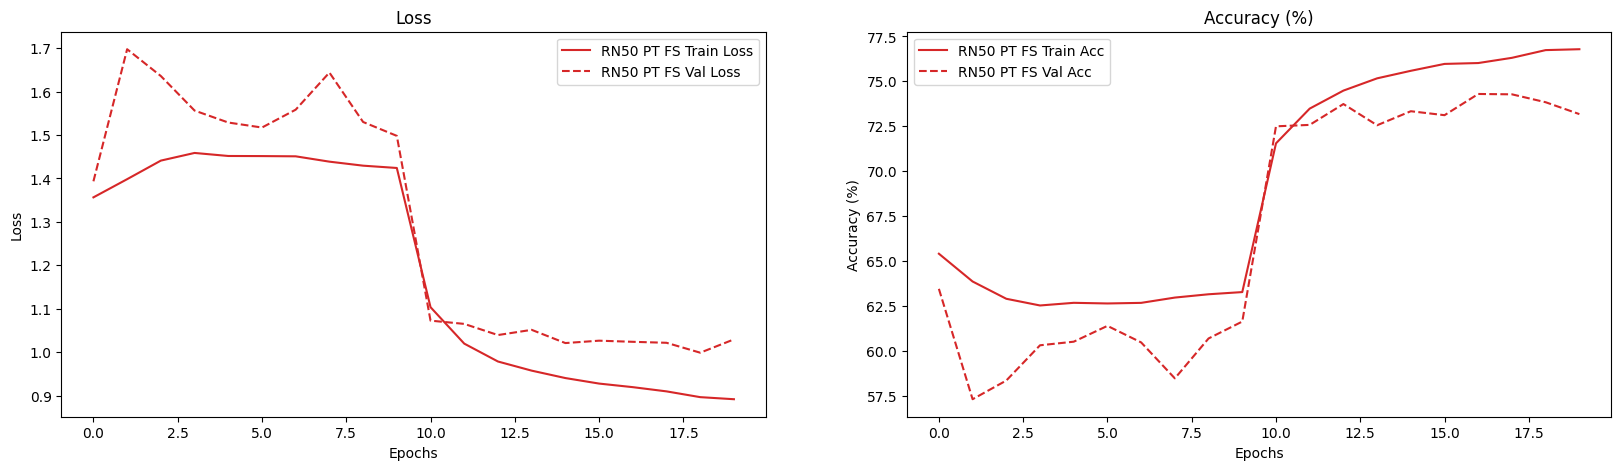

In [196]:
helper_plot_curves([history_rn50_fs], ["RN50 PT FS"])

Summary model performance

In [315]:
helper_summary_performance(result_rn50_fs, history_rn50_fs)

Test Performance:
Test Accuracy: 74.0999984741211
Test Loss: 0.9903897934436798
Min loss of training set = 0.8916603512965839
Min loss of validation set = 0.9987707664787769
Max accuracy of training set = 76.78917139907074
Max accuracy of validation set = 74.3
Train time = 353:22
Test time = 1:1


TP FP TN FN

In [316]:
import pandas as pd

helper_extract_tp_tn_fp_fn([rn50_fs_cm], [result_rn50_fs])

result_rn50_fs

Accuracy: 0.741000
Macro Recall: 0.741000
Difference: 0.0000000000


{'test_acc': tensor(74.1000, device='cuda:0'),
 'test_loss': 0.9903897934436798,
 'train_time': 21202.357566833496,
 'test_time': 61.23101568222046,
 'tp': tensor([38., 43., 41., 34., 37., 42., 44., 41., 44., 42., 41., 41., 43., 37.,
         39., 39., 38., 42., 47., 29., 25., 40., 29., 40., 41., 34., 38., 35.,
         44., 41., 36., 35., 37., 36., 37., 42., 45., 44., 43., 38., 43., 44.,
         36., 38., 44., 44., 37., 41., 25., 37., 27., 29., 36., 34., 27., 40.,
         41., 37., 36., 39., 32., 25., 30., 25., 15., 43., 41., 37., 34., 35.,
         32., 36., 34., 28., 28., 40., 27., 33., 29., 43., 34., 42., 34., 26.,
         32., 43., 39., 39., 26., 41., 36., 34., 33., 42., 40., 49., 39., 43.,
         47., 42.]),
 'tn': tensor([4936., 4948., 4945., 4944., 4932., 4940., 4945., 4945., 4939., 4939.,
         4945., 4938., 4948., 4935., 4931., 4940., 4934., 4941., 4947., 4941.,
         4930., 4942., 4942., 4936., 4941., 4940., 4934., 4923., 4940., 4939.,
         4943., 4932., 4946.

Save testing result

In [317]:
helper_replace2json(model_infor_rn50_fs['json_path'], 'result', clean_for_json(result_rn50_fs))
helper_replace2json(model_infor_rn50_fs['json_path'], 'history', clean_for_json(history_rn50_fs))

## [5] ViT-B/16 / PRETRAINED / FREEZE FULL BACKBONE

Pretrained : ViT-B/16

Freeze backbone level : full freeze

Head detection : basic

### [ViT] [FB] Create model

#### [ViT] [FB] Prepare data for train/resume

In [102]:
if model_infor_vitb16_pt_fb['train_type'] == 'new':
    helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'infor', model_infor_vitb16_pt_fb)
    helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'history', history_vitb16_pt_fb)
    helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'result', result_vitb16_pt_fb)
elif model_infor_vitb16_pt_fb['train_type'] == 'resume':
    history_vitb16_pt_fb = helper_get_value_json(model_infor_vitb16_pt_fb['json_path'], 'history')
    result_vitb16_pt_fb = helper_get_value_json(model_infor_vitb16_pt_fb['json_path'], 'result')

#### [ViT] [FB] Backbone and head

In [103]:
from torchvision import models

# load backbone
model_vitb16_pt_fb = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
model_best_vitb16_pt_fb = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

# display base model
print("[BASE] ViT B-16")
helper_display_model_info(model_vitb16_pt_fb)

# freeze full
if model_infor_vitb16_pt_fb['fine-tune'] == 'freezefull':
    for param in model_vitb16_pt_fb.parameters():
        param.requires_grad = False

# replace head classifier
model_vitb16_pt_fb.heads.head = basic_head_classifier(model_vitb16_pt_fb.heads.head.in_features, total_cls)
model_best_vitb16_pt_fb.heads.head = basic_head_classifier(model_best_vitb16_pt_fb.heads.head.in_features, total_cls)

# to device
model_vitb16_pt_fb = model_vitb16_pt_fb.to(device)
model_best_vitb16_pt_fb = model_best_vitb16_pt_fb.to(device)

print("[1] Pretrained model ViT B-16 with freeze full backbone")
helper_display_model_info(model_vitb16_pt_fb)

# update model information
if model_infor_vitb16_pt_fb['train_type'] == 'new':
    result_vitb16_pt_fb['total_params'] = sum(p.numel() for p in model_vitb16_pt_fb.parameters())
    result_vitb16_pt_fb['trainable_params'] = sum(p.numel() for p in model_vitb16_pt_fb.parameters() if p.requires_grad)
    helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'result', result_vitb16_pt_fb)
elif model_infor_vitb16_pt_fb['train_type'] == 'resume':
    print("[INFO] Resuming training for ViT B-16 with resume path = ", model_infor_vitb16_pt_fb['resume_path'])

[BASE] ViT B-16
=============== Model layer ===============
VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm

#### [ViT] [FB] Optimizer/Scheduler/LossFunction

In [104]:
model_vitb16_pt_fb_loss_func = modelLossFunction_CE()
if model_infor_vitb16_pt_fb['opt'] == 'adam':
    model_vitb16_pt_fb_opt = modelOpt_ADAM(model_vitb16_pt_fb, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1, model_type="vit")
    print("Using Adam optimizer")
elif model_infor_vitb16_pt_fb['opt'] == 'sgd':
    model_vitb16_pt_fb_opt = modelOpt_SGD(model_vitb16_pt_fb, lr_bb, model_type="vit")
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_vitb16_pt_fb['opt']}")

if model_infor_vitb16_pt_fb['scheduler'] == 'step':
    model_vitb16_pt_fb_scheduler = modelScheduler_StepLR(model_vitb16_pt_fb_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_vitb16_pt_fb['scheduler'] == 'cosine':
    if model_infor_vitb16_pt_fb['train-type'] == 'new':
        T_max = model_infor_vitb16_pt_fb['epoch']
    elif model_infor_vitb16_pt_fb['train-type'] == 'resume':
        T_max = model_infor_vitb16_pt_fb['epoch'] + model_infor_vitb16_pt_fb['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_vitb16_pt_fb['train-type']}")
    model_vitb16_pt_fb_scheduler = modelScheduler_CosineLR(model_vitb16_pt_fb_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_vitb16_pt_fb['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [ViT] [FB] Training loop

#### [ViT] [FB] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [ViT] [FB] Start new training

In [105]:
import torch
import os
import time

if model_infor_vitb16_pt_fb["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_vitb16_pt_fb_loss_train_min = 0.0
    global_vitb16_pt_fb_loss_val_min = 0.0
    global_vitb16_pt_fb_best_val_acc = 0.0

    # loop over epochs with
    ## model_vitb16_pt_fb.train() : set the model to training mode
    ## model_vitb16_pt_fb.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_vitb16_pt_fb["epoch_new"]):
        # training phase
        model_vitb16_pt_fb.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_vitb16_pt_fb(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_vitb16_pt_fb_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_vitb16_pt_fb_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_vitb16_pt_fb_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_vitb16_pt_fb_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_vitb16_pt_fb_loss_train_min or global_vitb16_pt_fb_loss_train_min == 0.0:
            global_vitb16_pt_fb_loss_train_min = train_loss_epoch
        
        # validation phase
        model_vitb16_pt_fb.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_vitb16_pt_fb(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_vitb16_pt_fb_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_vitb16_pt_fb_loss_val_min or global_vitb16_pt_fb_loss_val_min == 0.0:
            global_vitb16_pt_fb_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save history
        history_vitb16_pt_fb["train_loss"].append(train_loss_epoch)
        history_vitb16_pt_fb["train_acc"].append(train_acc_epoch)
        history_vitb16_pt_fb["val_loss"].append(val_loss_epoch)
        history_vitb16_pt_fb["val_acc"].append(val_acc_epoch)
        history_vitb16_pt_fb['epoch'].append(epoch + 1)
        history_vitb16_pt_fb['lr_bb'].append(model_vitb16_pt_fb_opt.get_lr()['lr_bb'])
        history_vitb16_pt_fb['lr_head'].append(model_vitb16_pt_fb_opt.get_lr()['lr_head'])

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_vitb16_pt_fb_best_val_acc:
            global_vitb16_pt_fb_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_vitb16_pt_fb.state_dict(),
                'optimizer_state_dict': model_vitb16_pt_fb_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_vitb16_pt_fb_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_vitb16_pt_fb_loss_train_min,
                'best_val_acc' : global_vitb16_pt_fb_best_val_acc,
                'history' : history_vitb16_pt_fb
            }
            torch.save(best_checkpoint, "./models/best_vitb16_pt_fb_model.pth")
            print(f"Saved new best model with val_acc = {global_vitb16_pt_fb_best_val_acc:.2f}%")

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_vitb16_pt_fb.state_dict(),
            'optimizer_state_dict': model_vitb16_pt_fb_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_vitb16_pt_fb_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_vitb16_pt_fb_loss_train_min,
            'best_val_acc' : global_vitb16_pt_fb_best_val_acc,
            'history' : history_vitb16_pt_fb
        }
        torch.save(last_checkpoint, "./models/last_vitb16_pt_fb_model.pth")

    end_train_time = time.time()
    result_vitb16_pt_fb['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

Start new training from epoch 0, all history will be store from the beginning
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 1801/1937
Done batch 1901/1937
[epoch = 0] [train_loss = 0.2724] [train_acc = 94.64%] [val_loss = 0.4438] [val_acc = 89.82%]
Saved new best model with val_acc = 89.82%
Done batch 1/1937
Done batch 101/1937
Done batch 201/1937
Done batch 301/1937
Done batch 401/1937
Done batch 501/1937
Done batch 601/1937
Done batch 701/1937
Done batch 801/1937
Done batch 901/1937
Done batch 1001/1937
Done batch 1101/1937
Done batch 1201/1937
Done batch 1301/1937
Done batch 1401/1937
Done batch 1501/1937
Done batch 1601/1937
Done batch 1701/1937
Done batch 

#### [ViT] [FB] Resume training

In [106]:
import os
import torch

if model_infor_vitb16_pt_fb["train_type"] == "resume":
    if model_infor_vitb16_pt_fb['resume_path'] is not None:
        last_checkpoint_path = model_infor_vitb16_pt_fb['resume_path']

        if not os.path.exists(last_checkpoint_path):
            raise FileNotFoundError(f"Checkpoint file not found at {last_checkpoint_path}")
        else:
            cont_epoch = 0
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_vitb16_pt_fb.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_vitb16_pt_fb_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_vitb16_pt_fb_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_vitb16_pt_fb = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_vitb16_pt_fb_loss_train_min = checkpoint['min_train_loss']
            global_vitb16_pt_fb_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


In [ ]:
import time

if model_infor_vitb16_pt_fb["train_type"] == "resume":
    if model_infor_vitb16_pt_fb['resume_path'] is not None:
        
        start_time = time.time()
        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_vitb16_pt_fb["epoch_resume"]):
            model_vitb16_pt_fb.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_vitb16_pt_fb(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_vitb16_pt_fb_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_vitb16_pt_fb_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_vitb16_pt_fb_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_vitb16_pt_fb_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_vitb16_pt_fb_loss_train_min or global_vitb16_pt_fb_loss_train_min == 0.0:
                global_vitb16_pt_fb_loss_train_min = train_loss_epoch
            
            # validation phase
            model_vitb16_pt_fb.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_vitb16_pt_fb(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_vitb16_pt_fb_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_vitb16_pt_fb_loss_val_min or global_vitb16_pt_fb_loss_val_min == 0.0:
                global_vitb16_pt_fb_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_vitb16_pt_fb_best_val_acc:
                global_vitb16_pt_fb_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_vitb16_pt_fb.state_dict(),
                    'optimizer_state_dict': model_vitb16_pt_fb_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_vitb16_pt_fb_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_vitb16_pt_fb_loss_train_min,
                    'best_val_acc': global_vitb16_pt_fb_best_val_acc,
                    'history' : history_vitb16_pt_fb
                }
                torch.save(best_checkpoint, "./models/best_vitb16_pt_fb_model.pth")
                print(f"Saved new best model with val_acc = {global_vitb16_pt_fb_best_val_acc:.2f}%")

            # save history
            history_vitb16_pt_fb["train_loss"].append(train_loss_epoch)
            history_vitb16_pt_fb["train_acc"].append(train_acc_epoch)
            history_vitb16_pt_fb["val_loss"].append(val_loss_epoch)
            history_vitb16_pt_fb["val_acc"].append(val_acc_epoch)
            history_vitb16_pt_fb['epoch'].append(epoch + 1)
            history_vitb16_pt_fb['lr_bb'].append(model_vitb16_pt_fb_opt.get_lr()['lr_bb'])
            history_vitb16_pt_fb['lr_head'].append(model_vitb16_pt_fb_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_vitb16_pt_fb.state_dict(),
                'optimizer_state_dict': model_vitb16_pt_fb_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_vitb16_pt_fb_scheduler.scheduler.state_dict(),
                'min_train_loss': global_vitb16_pt_fb_loss_train_min,
                'best_val_acc': global_vitb16_pt_fb_best_val_acc,
                'history' : history_vitb16_pt_fb
            }
            torch.save(last_checkpoint, f'./models/last_vitb16_pt_fb_model_from_{cont_epoch}.pth')

        end_train_time = time.time()
        result_vitb16_pt_fb['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


### [ViT] [FB] Executing testing

Testing with best model which return maximum accuracy from validation set

In [108]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_vitb16_pt_fb_model.pth", map_location=device)

# load weights
model_best_vitb16_pt_fb.load_state_dict(checkpoint['model_state_dict'])

model_best_vitb16_pt_fb.to(device)
model_best_vitb16_pt_fb.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\1688910375.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_vitb16_pt_fb_model.p

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [318]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_vitb16_pt_fb(inputs) # input => ViT-B/16 => output logits z

        test_loss_mean_batch = model_vitb16_pt_fb_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_vitb16_pt_fb['test_time'] = end_test_time - start_time
result_vitb16_pt_fb['test_loss'] = test_loss_total / test_sample_total
result_vitb16_pt_fb['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100

test_preds = torch.cat(test_preds)
act_preds = torch.cat(act_preds)

vitb16_pt_fb_cm.reset()
vitb16_pt_fb_cm.update(test_preds, act_preds)

print(f"[test_loss = {result_vitb16_pt_fb['test_loss']:.4f}] [test_acc = {result_vitb16_pt_fb['test_acc']:.2f}%]")

[test_loss = 0.1702] [test_acc = 95.78%]


### [ViT] [FB] Evaluation

Loss/Accuracy of training/validation set

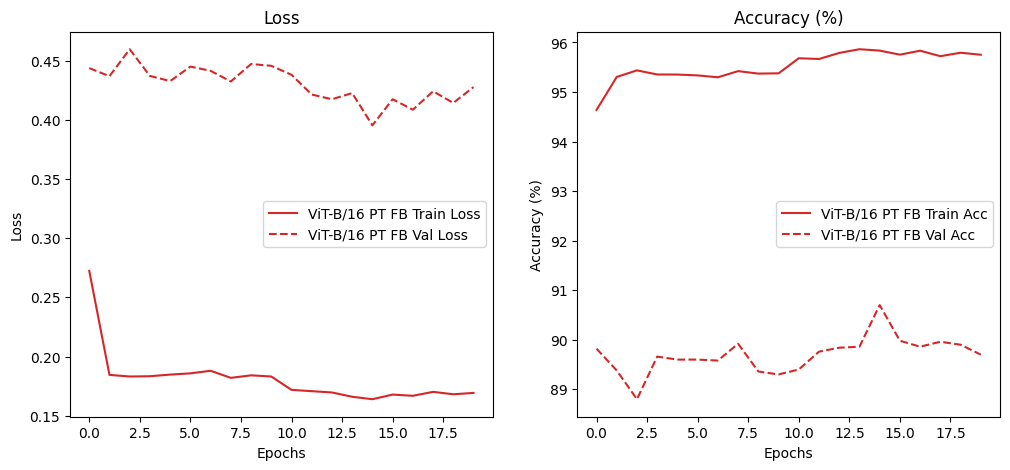

In [110]:
helper_plot_curves([history_vitb16_pt_fb], ["ViT-B/16 PT FB"])

Summary model performance

In [319]:
helper_summary_performance(result_vitb16_pt_fb, history_vitb16_pt_fb)

Test Performance:
Test Accuracy: 95.77999877929688
Test Loss: 0.1702100240446627
Min loss of training set = 0.1639381440992962
Min loss of validation set = 0.39538088977485897
Max accuracy of training set = 95.86425529168818
Max accuracy of validation set = 90.7
Train time = 226:10
Test time = 5:50


TP FP TN FN

In [320]:
import pandas as pd

helper_extract_tp_tn_fp_fn([vitb16_pt_fb_cm], [result_vitb16_pt_fb])

result_vitb16_pt_fb

Accuracy: 0.957800
Macro Recall: 0.957800
Difference: 0.0000000000


{'test_acc': tensor(95.7800, device='cuda:0'),
 'test_loss': 0.1702100240446627,
 'train_time': 13570.024961233139,
 'test_time': 350.64883947372437,
 'tp': tensor([46., 48., 47., 44., 44., 49., 47., 49., 48., 49., 48., 49., 49., 49.,
         49., 48., 49., 48., 50., 46., 46., 50., 48., 49., 48., 49., 48., 50.,
         49., 49., 49., 49., 49., 48., 48., 49., 49., 48., 49., 47., 48., 49.,
         47., 49., 49., 50., 46., 48., 49., 48., 47., 48., 48., 47., 47., 49.,
         48., 47., 49., 47., 48., 45., 46., 48., 46., 48., 46., 49., 47., 47.,
         47., 49., 50., 43., 47., 49., 43., 49., 45., 50., 47., 49., 48., 47.,
         49., 49., 48., 47., 47., 46., 49., 49., 46., 48., 48., 49., 49., 48.,
         50., 47.]),
 'tn': tensor([4950., 4950., 4947., 4948., 4941., 4949., 4950., 4949., 4946., 4949.,
         4950., 4947., 4949., 4950., 4947., 4947., 4948., 4946., 4949., 4948.,
         4948., 4949., 4949., 4949., 4949., 4948., 4950., 4947., 4950., 4948.,
         4949., 4948., 4949

Save testing result

In [321]:
helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'result', clean_for_json(result_vitb16_pt_fb))
helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'history', clean_for_json(history_vitb16_pt_fb))

## [6] [Non-train] ViT-B/16 / PRETRAINED / PARTIAL FINE-TUNE

Pretrained : ViT-B/16

Freeze backbone level : partial fine-tune

Head detection : basic

### [ViT] [FP] Create model

#### [ViT] [FP] Prepare data for train/resume

In [135]:
if model_infor_vitb16_pt_fp['train_type'] == 'new':
    helper_replace2json(model_infor_vitb16_pt_fp['json_path'], 'infor', model_infor_vitb16_pt_fp)
    helper_replace2json(model_infor_vitb16_pt_fp['json_path'], 'history', history_vitb16_pt_fp)
    helper_replace2json(model_infor_vitb16_pt_fp['json_path'], 'result', result_vitb16_pt_fp)
elif model_infor_vitb16_pt_fp['train_type'] == 'resume':
    history_vitb16_pt_fp = helper_get_value_json(model_infor_vitb16_pt_fp['json_path'], 'history')
    result_vitb16_pt_fp = helper_get_value_json(model_infor_vitb16_pt_fp['json_path'], 'result')

#### [ViT] [FP] Backbone and head

In [136]:
from torchvision import models

# load backbone
model_vitb16_pt_fp = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
model_best_vitb16_pt_fp = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

# display base model
print("[BASE] ViT B-16")
helper_display_model_info(model_vitb16_pt_fp)

# freeze full
if model_infor_vitb16_pt_fp['fine-tune'] == 'freezefull':
    for param in model_vitb16_pt_fp.parameters():
        param.requires_grad = False

if model_infor_vitb16_pt_fp['fine-tune'] == 'partial':
    print("Partial fine-tuning one last encoder layers")
    for param in model_vitb16_pt_fp.parameters():
        param.requires_grad = False
    for block in model_vitb16_pt_fp.encoder.layers[-1:]:
        for param in block.parameters():
            param.requires_grad = True
    for param in model_vitb16_pt_fp.heads.head.parameters():
        param.requires_grad = True
            
# replace head classifier
model_vitb16_pt_fp.heads.head = basic_head_classifier(model_vitb16_pt_fp.heads.head.in_features, total_cls)
model_best_vitb16_pt_fp.heads.head = basic_head_classifier(model_best_vitb16_pt_fp.heads.head.in_features, total_cls)

# to device
model_vitb16_pt_fp = model_vitb16_pt_fp.to(device)
model_best_vitb16_pt_fp = model_best_vitb16_pt_fp.to(device)

print("[1] Pretrained model ViT B-16 with freeze full backbone")
helper_display_model_info(model_vitb16_pt_fp)

# update model information
if model_infor_vitb16_pt_fp['train_type'] == 'new':
    result_vitb16_pt_fp['total_params'] = sum(p.numel() for p in model_vitb16_pt_fp.parameters())
    result_vitb16_pt_fp['trainable_params'] = sum(p.numel() for p in model_vitb16_pt_fp.parameters() if p.requires_grad)
    helper_replace2json(model_infor_vitb16_pt_fp['json_path'], 'result', result_vitb16_pt_fp)
elif model_infor_vitb16_pt_fp['train_type'] == 'resume':
    print("[INFO] Resuming training for ViT B-16 with resume path = ", model_infor_vitb16_pt_fp['resume_path'])

[BASE] ViT B-16
=============== Model layer ===============
VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm

#### [ViT] [FP] Optimizer/Scheduler/LossFunction

In [137]:
model_vitb16_pt_fp_loss_func = modelLossFunction_CE()
if model_infor_vitb16_pt_fp['opt'] == 'adam':
    model_vitb16_pt_fp_opt = modelOpt_ADAM(model_vitb16_pt_fp, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1, model_type="vit")
    print("Using Adam optimizer")
elif model_infor_vitb16_pt_fp['opt'] == 'sgd':
    model_vitb16_pt_fp_opt = modelOpt_SGD(model_vitb16_pt_fp, lr_bb, model_type="vit")
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_vitb16_pt_fp['opt']}")

if model_infor_vitb16_pt_fp['scheduler'] == 'step':
    model_vitb16_pt_fp_scheduler = modelScheduler_StepLR(model_vitb16_pt_fp_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_vitb16_pt_fp['scheduler'] == 'cosine':
    if model_infor_vitb16_pt_fp['train-type'] == 'new':
        T_max = model_infor_vitb16_pt_fp['epoch']
    elif model_infor_vitb16_pt_fp['train-type'] == 'resume':
        T_max = model_infor_vitb16_pt_fp['epoch'] + model_infor_vitb16_pt_fp['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_vitb16_pt_fp['train-type']}")
    model_vitb16_pt_fp_scheduler = modelScheduler_CosineLR(model_vitb16_pt_fp_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_vitb16_pt_fp['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [ViT] [FP] Training loop

#### [ViT] [FP] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [ViT] [FP] Start new training

In [ ]:
import torch
import os
import time

if model_infor_vitb16_pt_fp["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_vitb16_pt_fp_loss_train_min = 0.0
    global_vitb16_pt_fp_loss_val_min = 0.0
    global_vitb16_pt_fp_best_val_acc = 0.0

    # loop over epochs with
    ## model_vitb16_pt_fp.train() : set the model to training mode
    ## model_vitb16_pt_fp.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_vitb16_pt_fp["epoch_new"]):
        # training phase
        model_vitb16_pt_fp.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_vitb16_pt_fp(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_vitb16_pt_fp_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_vitb16_pt_fp_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_vitb16_pt_fp_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_vitb16_pt_fp_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_vitb16_pt_fp_loss_train_min or global_vitb16_pt_fp_loss_train_min == 0.0:
            global_vitb16_pt_fp_loss_train_min = train_loss_epoch
        
        # validation phase
        model_vitb16_pt_fp.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_vitb16_pt_fp(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_vitb16_pt_fp_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_vitb16_pt_fp_loss_val_min or global_vitb16_pt_fp_loss_val_min == 0.0:
            global_vitb16_pt_fp_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save history
        history_vitb16_pt_fp["train_loss"].append(train_loss_epoch)
        history_vitb16_pt_fp["train_acc"].append(train_acc_epoch)
        history_vitb16_pt_fp["val_loss"].append(val_loss_epoch)
        history_vitb16_pt_fp["val_acc"].append(val_acc_epoch)
        history_vitb16_pt_fp['epoch'].append(epoch + 1)
        history_vitb16_pt_fp['lr_bb'].append(model_vitb16_pt_fp_opt.get_lr()['lr_bb'])
        history_vitb16_pt_fp['lr_head'].append(model_vitb16_pt_fp_opt.get_lr()['lr_head'])

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_vitb16_pt_fp_best_val_acc:
            global_vitb16_pt_fp_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_vitb16_pt_fp.state_dict(),
                'optimizer_state_dict': model_vitb16_pt_fp_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_vitb16_pt_fp_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_vitb16_pt_fp_loss_train_min,
                'best_val_acc' : global_vitb16_pt_fp_best_val_acc,
                'history' : history_vitb16_pt_fp
            }
            torch.save(best_checkpoint, "./models/best_vitb16_pt_fp_model.pth")
            print(f"Saved new best model with val_acc = {global_vitb16_pt_fp_best_val_acc:.2f}%")

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_vitb16_pt_fp.state_dict(),
            'optimizer_state_dict': model_vitb16_pt_fp_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_vitb16_pt_fp_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_vitb16_pt_fp_loss_train_min,
            'best_val_acc' : global_vitb16_pt_fp_best_val_acc,
            'history' : history_vitb16_pt_fp
        }
        torch.save(last_checkpoint, "./models/last_vitb16_pt_fp_model.pth")

    end_train_time = time.time()
    result_vitb16_pt_fp['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

#### [ViT] [FP] Resume training

In [ ]:
import os
import torch

if model_infor_vitb16_pt_fp["train_type"] == "resume":
    if model_infor_vitb16_pt_fp['resume_path'] is not None:
        last_checkpoint_path = model_infor_vitb16_pt_fp['resume_path']

        if not os.path.exists(last_checkpoint_path):
            raise FileNotFoundError(f"Checkpoint file not found at {last_checkpoint_path}")
        else:
            cont_epoch = 0
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_vitb16_pt_fp.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_vitb16_pt_fp_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_vitb16_pt_fp_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_vitb16_pt_fp = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_vitb16_pt_fp_loss_train_min = checkpoint['min_train_loss']
            global_vitb16_pt_fp_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


In [ ]:
import time

if model_infor_vitb16_pt_fp["train_type"] == "resume":
    if model_infor_vitb16_pt_fp['resume_path'] is not None:
        
        start_time = time.time()
        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_vitb16_pt_fp["epoch_resume"]):
            model_vitb16_pt_fp.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_vitb16_pt_fp(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_vitb16_pt_fp_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_vitb16_pt_fp_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_vitb16_pt_fp_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_vitb16_pt_fp_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_vitb16_pt_fp_loss_train_min or global_vitb16_pt_fp_loss_train_min == 0.0:
                global_vitb16_pt_fp_loss_train_min = train_loss_epoch
            
            # validation phase
            model_vitb16_pt_fp.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_vitb16_pt_fp(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_vitb16_pt_fp_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_vitb16_pt_fp_loss_val_min or global_vitb16_pt_fp_loss_val_min == 0.0:
                global_vitb16_pt_fp_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_vitb16_pt_fp_best_val_acc:
                global_vitb16_pt_fp_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_vitb16_pt_fp.state_dict(),
                    'optimizer_state_dict': model_vitb16_pt_fp_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_vitb16_pt_fp_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_vitb16_pt_fp_loss_train_min,
                    'best_val_acc': global_vitb16_pt_fp_best_val_acc,
                    'history' : history_vitb16_pt_fp
                }
                torch.save(best_checkpoint, "./models/best_vitb16_pt_fp_model.pth")
                print(f"Saved new best model with val_acc = {global_vitb16_pt_fp_best_val_acc:.2f}%")

            # save history
            history_vitb16_pt_fp["train_loss"].append(train_loss_epoch)
            history_vitb16_pt_fp["train_acc"].append(train_acc_epoch)
            history_vitb16_pt_fp["val_loss"].append(val_loss_epoch)
            history_vitb16_pt_fp["val_acc"].append(val_acc_epoch)
            history_vitb16_pt_fp['epoch'].append(epoch + 1)
            history_vitb16_pt_fp['lr_bb'].append(model_vitb16_pt_fp_opt.get_lr()['lr_bb'])
            history_vitb16_pt_fp['lr_head'].append(model_vitb16_pt_fp_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_vitb16_pt_fp.state_dict(),
                'optimizer_state_dict': model_vitb16_pt_fp_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_vitb16_pt_fp_scheduler.scheduler.state_dict(),
                'min_train_loss': global_vitb16_pt_fp_loss_train_min,
                'best_val_acc': global_vitb16_pt_fp_best_val_acc,
                'history' : history_vitb16_pt_fp
            }
            torch.save(last_checkpoint, f'./models/last_vitb16_pt_fp_model_from_{cont_epoch}.pth')

        end_train_time = time.time()
        result_vitb16_pt_fp['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

Resume mode is not enabled


### [ViT] [FP] Executing testing

Testing with best model which return maximum accuracy from validation set

In [ ]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_vitb16_pt_fp_model.pth", map_location=device)

# load weights
model_best_vitb16_pt_fp.load_state_dict(checkpoint['model_state_dict'])

model_best_vitb16_pt_fp.to(device)
model_best_vitb16_pt_fp.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\1688910375.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_vitb16_pt_fb_model.p

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [ ]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_vitb16_pt_fp(inputs) # input => ViT-B/16 => output logits z

        test_loss_mean_batch = model_vitb16_pt_fp_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_vitb16_pt_fp['test_time'] = end_test_time - start_time
result_vitb16_pt_fp['test_loss'] = test_loss_total / test_sample_total
result_vitb16_pt_fp['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100
vitb16_pt_fp_cm(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_vitb16_pt_fp['test_loss']:.4f}] [test_acc = {result_vitb16_pt_fp['test_acc']:.2f}%]")

[test_loss = 0.1780] [test_acc = 95.86%]


### [ViT] [FP] Evaluation

Loss/Accuracy of training/validation set

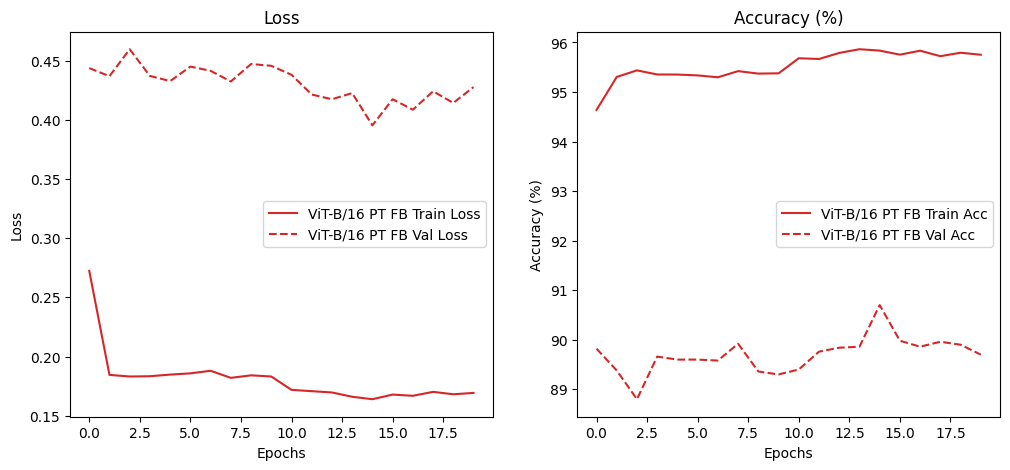

In [ ]:
helper_plot_curves([history_vitb16_pt_fp], ["ViT-B/16 PT FP"])

Summary model performance

In [ ]:
helper_summary_performance(result_vitb16_pt_fp, history_vitb16_pt_fp)

Test Performance:
Test Accuracy: 95.86000061035156
Test Loss: 0.17803310214281082
Min loss of training set = 0.1639381440992962
Min loss of validation set = 0.39538088977485897
Max accuracy of training set = 95.86425529168818
Max accuracy of validation set = 90.7
Train time = 226:10
Test time = 0:32


TP FP TN FN

In [223]:
import pandas as pd

helper_extract_tp_tn_fp_fn([vitb16_pt_fp_cm], [result_vitb16_pt_fp])

result_vitb16_pt_fp

{'test_acc': 0.0,
 'test_loss': 0.0,
 'train_time': 0.0,
 'test_time': 0.0,
 'tp': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0]),
 'tn': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0]),
 'fp': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

Save testing result

In [ ]:
helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'result', clean_for_json(result_vitb16_pt_fb))
helper_replace2json(model_infor_vitb16_pt_fb['json_path'], 'history', clean_for_json(history_vitb16_pt_fb))

## [7] [Non-train] ViT-B/16 / PRETRAINED / FULL FINE-TUNE

Pretrained : ViT-B/16

Freeze backbone level : full fine-tune

Head detection : basic

### [ViT] [FT] Create model

#### [ViT] [FT] Prepare data for train/resume

In [140]:
if model_infor_vitb16_pt_ft['train_type'] == 'new':
    helper_replace2json(model_infor_vitb16_pt_ft['json_path'], 'infor', model_infor_vitb16_pt_ft)
    helper_replace2json(model_infor_vitb16_pt_ft['json_path'], 'history', history_vitb16_pt_ft)
    helper_replace2json(model_infor_vitb16_pt_ft['json_path'], 'result', result_vitb16_pt_ft)
elif model_infor_vitb16_pt_ft['train_type'] == 'resume':
    history_vitb16_pt_ft = helper_get_value_json(model_infor_vitb16_pt_ft['json_path'], 'history')
    result_vitb16_pt_ft = helper_get_value_json(model_infor_vitb16_pt_ft['json_path'], 'result')

#### [ViT] [FT] Backbone and head

In [141]:
from torchvision import models

# load backbone
model_vitb16_pt_ft = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)
model_best_vitb16_pt_ft = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

# display base model
print("[BASE] ViT-B/16")
helper_display_model_info(model_vitb16_pt_ft)

# freeze full
if model_infor_vitb16_pt_ft['fine-tune'] == 'freezefull':
    for param in model_vitb16_pt_ft.parameters():
        param.requires_grad = False

# replace head classifier
model_vitb16_pt_ft.heads.head = basic_head_classifier(model_vitb16_pt_ft.heads.head.in_features, total_cls)
model_best_vitb16_pt_ft.heads.head = basic_head_classifier(model_best_vitb16_pt_ft.heads.head.in_features, total_cls)

# to device
model_vitb16_pt_ft = model_vitb16_pt_ft.to(device)
model_best_vitb16_pt_ft = model_best_vitb16_pt_ft.to(device)

print("[1] Pretrained model ViT-B/16 with freeze full backbone")
helper_display_model_info(model_vitb16_pt_ft)

# update model information
if model_infor_vitb16_pt_ft['train_type'] == 'new':
    result_vitb16_pt_ft['total_params'] = sum(p.numel() for p in model_vitb16_pt_ft.parameters())
    result_vitb16_pt_ft['trainable_params'] = sum(p.numel() for p in model_vitb16_pt_ft.parameters() if p.requires_grad)
    helper_replace2json(model_infor_vitb16_pt_ft['json_path'], 'result', result_vitb16_pt_ft)
elif model_infor_vitb16_pt_ft['train_type'] == 'resume':
    print("[INFO] Resuming training for ViT B-16 with resume path = ", model_infor_vitb16_pt_ft['resume_path'])

[BASE] ViT-B/16
=============== Model layer ===============
VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm

#### [ViT] [FT] Optimizer/Scheduler/LossFunction

In [142]:
model_vitb16_pt_ft_loss_func = modelLossFunction_CE()
if model_infor_vitb16_pt_ft['opt'] == 'adam':
    model_vitb16_pt_ft_opt = modelOpt_ADAM(model_vitb16_pt_ft, lr_bb, lr_head, weight_decay_a1, betas_a1, eps_a1, model_type="vit")
    print("Using Adam optimizer")
elif model_infor_vitb16_pt_ft['opt'] == 'sgd':
    model_vitb16_pt_ft_opt = modelOpt_SGD(model_vitb16_pt_ft, lr_bb, model_type="vit")
    print("Using SGD optimizer")
else:
    raise ValueError(f"Unsupported optimizer type: {model_infor_vitb16_pt_ft['opt']}")

if model_infor_vitb16_pt_ft['scheduler'] == 'step':
    model_vitb16_pt_ft_scheduler = modelScheduler_StepLR(model_vitb16_pt_ft_opt.optimizer, step_size=step_size, gamma=gamma)
    print("Using StepLR scheduler")
elif model_infor_vitb16_pt_ft['scheduler'] == 'cosine':
    if model_infor_vitb16_pt_ft['train-type'] == 'new':
        T_max = model_infor_vitb16_pt_ft['epoch']
    elif model_infor_vitb16_pt_ft['train-type'] == 'resume':
        T_max = model_infor_vitb16_pt_ft['epoch'] + model_infor_vitb16_pt_ft['resume-epoch']
    else:
        raise ValueError(f"Unsupported train-type: {model_infor_vitb16_pt_ft['train-type']}")
    model_vitb16_pt_ft_scheduler = modelScheduler_CosineLR(model_vitb16_pt_ft_opt.optimizer, T_max=T_max, eta_min=eta_min)
    print("Using CosineAnnealingLR scheduler")
else:
    raise ValueError(f"Unsupported scheduler type: {model_infor_vitb16_pt_ft['scheduler']}")

Using Adam optimizer
Using StepLR scheduler


### [ViT] [FT] Training loop

#### [ViT] [FT] Testing training loop with subset

In [ ]:
# # create subset for testing

# import torch
# from torch.utils.data import Subset
# import numpy as np

# subset_train = len(dataset_train_rn50_ft)
# subset_ratio = 0.05 

# np.random.seed(42)
# subset_indices = np.random.choice(subset_train, int(subset_train * subset_ratio), replace=False)

# train_subset = Subset(dataset_train_rn50_ft, subset_indices)

# dataloader_train_subset = torch.utils.data.DataLoader(
#     train_subset,
#     batch_size=32,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True
# )

#### [ViT] [FT] Start new training

In [ ]:
import torch
import os
import time

if model_infor_vitb16_pt_ft["train_type"] == "new":
    print("Start new training from epoch 0, all history will be store from the beginning")

    # initialize global min loss and best validation accuracy for the current epoch
    global_vitb16_pt_ft_loss_train_min = 0.0
    global_vitb16_pt_ft_loss_val_min = 0.0
    global_vitb16_pt_ft_best_val_acc = 0.0

    # loop over epochs with
    ## model_vitb16_pt_ft.train() : set the model to training mode
    ## model_vitb16_pt_ft.eval() : set the model to evaluation mode for validation
    ## torch.no_grad() : disable gradient calculation for validation to validate model performance for each epoch
    start_time = time.time()
    for epoch in range(model_infor_vitb16_pt_ft["epoch_new"]):
        # training phase
        model_vitb16_pt_ft.train() # enable training mode

        # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
        ## train_loss_total : loss calculate on total training samples for the current epoch
        ## train_acc_total : accuracy calculated on total training samples for the current epoch
        ## train_total : total number of training samples for the current epoch
        ## loss_mean_batch : loss calculated for the current batch
        train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
        train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
        train_loss_epoch, train_acc_epoch = 0.0, 0.0

        for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
            inputs, targets = inputs.to(device), targets.to(device)
            output_z = model_vitb16_pt_ft(inputs) # input => CNN => output logits z
            train_loss_mean_batch = model_vitb16_pt_ft_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

            # update weights
            model_vitb16_pt_ft_opt.zero_grad()
            train_loss_mean_batch.backward()
            model_vitb16_pt_ft_opt.step()

            # loss calculation and accuracy for the current batch
            train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
            predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
            train_sample_total += targets.size(0)
            train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            if batch_idx % 100 == 0:
                fd
                print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

        # update LR by optimizer
        model_vitb16_pt_ft_scheduler.scheduler_step()

        train_loss_epoch = train_loss_total / train_sample_total
        train_acc_epoch = (train_acc_total / train_sample_total)*100

        if train_loss_epoch < global_vitb16_pt_ft_loss_train_min or global_vitb16_pt_ft_loss_train_min == 0.0:
            global_vitb16_pt_ft_loss_train_min = train_loss_epoch
        
        # validation phase
        model_vitb16_pt_ft.eval() # enable evaluation mode

        # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
        ## val_loss_total : loss calculated on total validation samples for the current epoch
        ## val_acc_total : accuracy calculated on total validation samples for the current epoch
        ## val_sample_total : total number of validation samples for the current epoch
        ## val_loss_mean_batch : loss calculated for the current batch
        val_loss_epoch, val_acc_epoch = 0.0, 0.0
        val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

        with torch.no_grad():
            for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)

                output_z = model_vitb16_pt_ft(inputs) # input => MLP => output logits z

                val_loss_mean_batch = model_vitb16_pt_ft_loss_func(output_z, targets)

                val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                val_sample_total += targets.size(0)
                val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

        val_loss_epoch = val_loss_total / val_sample_total
        val_acc_epoch = (val_acc_total / val_sample_total)*100
        
        if val_loss_epoch < global_vitb16_pt_ft_loss_val_min or global_vitb16_pt_ft_loss_val_min == 0.0:
            global_vitb16_pt_ft_loss_val_min = val_loss_epoch

        print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

        # save checkpoint of model which model return the best validation accuracy
        if val_acc_epoch > global_vitb16_pt_ft_best_val_acc:
            global_vitb16_pt_ft_best_val_acc = val_acc_epoch
            best_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_vitb16_pt_ft.state_dict(),
                'optimizer_state_dict': model_vitb16_pt_ft_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_vitb16_pt_ft_scheduler.scheduler.state_dict(),
                'min_train_loss' : global_vitb16_pt_ft_loss_train_min,
                'best_val_acc' : global_vitb16_pt_ft_best_val_acc,
                'history': history_vitb16_pt_ft
            }
            torch.save(best_checkpoint, "./models/best_vitb16_pt_ft_model.pth")
            print(f"Saved new best model with val_acc = {global_vitb16_pt_ft_best_val_acc:.2f}%")

        # save history
        history_vitb16_pt_ft["train_loss"].append(train_loss_epoch)
        history_vitb16_pt_ft["train_acc"].append(train_acc_epoch)
        history_vitb16_pt_ft["val_loss"].append(val_loss_epoch)
        history_vitb16_pt_ft["val_acc"].append(val_acc_epoch)
        history_vitb16_pt_ft['epoch'].append(epoch + 1)
        history_vitb16_pt_ft['lr_bb'].append(model_vitb16_pt_ft_opt.get_lr()['lr_bb'])
        history_vitb16_pt_ft['lr_head'].append(model_vitb16_pt_ft_opt.get_lr()['lr_head'])

        last_checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model_vitb16_pt_ft.state_dict(),
            'optimizer_state_dict': model_vitb16_pt_ft_opt.optimizer.state_dict(),
            'scheduler_state_dict': model_vitb16_pt_ft_scheduler.scheduler.state_dict(),
            'min_train_loss' : global_vitb16_pt_ft_loss_train_min,
            'best_val_acc' : global_vitb16_pt_ft_best_val_acc,
            'history': history_vitb16_pt_ft
        }
        torch.save(last_checkpoint, './models/last_vitb16_pt_ft_model.pth')

    end_train_time = time.time()
    result_vitb16_pt_ft['train_time'] = end_train_time - start_time
else:
    print("Training was not performed.")

#### [ViT] [FT] Resume training

In [ ]:
import os
import torch
from pathlib import Path

cont_epoch = 0

if model_infor_vitb16_pt_ft["train_type"] == "resume":
    if model_infor_vitb16_pt_ft['resume_path'] is not None:
        last_checkpoint_path = model_infor_vitb16_pt_ft['resume_path']

        if os.path.exists(Path(last_checkpoint_path)):
            # load last checkpoint
            checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)

            # load weights
            model_vitb16_pt_ft.load_state_dict(checkpoint['model_state_dict'])

            # load optimizer & scheduler
            model_vitb16_pt_ft_opt.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            model_vitb16_pt_ft_scheduler.scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

            # load last epoch
            cont_epoch = checkpoint['epoch']

            # load history
            history_vitb16_pt_ft = checkpoint['history']

            # load global_min_loss_train, global_best_val_acc
            global_vitb16_pt_ft_loss_train_min = checkpoint['min_train_loss']
            global_vitb16_pt_ft_best_val_acc = checkpoint['best_val_acc']

            print(f"Resuming training from epoch {cont_epoch} of last checkpoint store at {last_checkpoint_path}")
        else:
            print(f"Last checkpoint not found at {last_checkpoint_path}")
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

In [ ]:
import time

if model_infor_vitb16_pt_ft["train_type"] == "resume":
    if model_infor_vitb16_pt_ft['resume_path'] is not None:
        start_time = time.time()

        print(f"Starting training from epoch {cont_epoch}")
        for epoch in range(cont_epoch, cont_epoch + model_infor_vitb16_pt_ft["epoch_resume"]):
            model_vitb16_pt_ft.train() # enable training mode

            # initialize tracking parameter for each epoch, then it will calculate then sum over all batches
            ## train_loss_total : loss calculate on total training samples for the current epoch
            ## train_acc_total : accuracy calculated on total training samples for the current epoch
            ## train_total : total number of training samples for the current epoch
            ## loss_mean_batch : loss calculated for the current batch
            train_loss_mean_batch = 0.0 # loss calculate by nn.CrossEntropyLoss return the mean of the batch
            train_loss_total, train_acc_total, train_sample_total = 0.0, 0.0, 0
            train_loss_epoch, train_acc_epoch = 0.0, 0.0

            for batch_idx, (inputs, targets) in enumerate(dataloader_train_rn50_ft):
                inputs, targets = inputs.to(device), targets.to(device)
                output_z = model_vitb16_pt_ft(inputs) # input => CNN => output logits z
                train_loss_mean_batch = model_vitb16_pt_ft_loss_func(output_z, targets) # included softmax for output ligits and calculate the loss in testing set

                # update weights
                model_vitb16_pt_ft_opt.zero_grad()
                train_loss_mean_batch.backward()
                model_vitb16_pt_ft_opt.step()

                # loss calculation and accuracy for the current batch
                train_loss_total += train_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                train_sample_total += targets.size(0)
                train_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

                if batch_idx % 100 == 0:
                    print(f"Done batch {batch_idx+1}/{len(dataloader_train_rn50_ft)}")

            # update LR by optimizer
            model_vitb16_pt_ft_scheduler.scheduler_step()

            train_loss_epoch = train_loss_total / train_sample_total
            train_acc_epoch = (train_acc_total / train_sample_total)*100

            if train_loss_epoch < global_vitb16_pt_ft_loss_train_min or global_vitb16_pt_ft_loss_train_min == 0.0:
                global_vitb16_pt_ft_loss_train_min = train_loss_epoch
            
            # validation phase
            model_vitb16_pt_ft.eval() # enable evaluation mode

            # Initialize tracking parameter for validation phase, then it will calculate then sum over all batches
            ## val_loss_total : loss calculated on total validation samples for the current epoch
            ## val_acc_total : accuracy calculated on total validation samples for the current epoch
            ## val_sample_total : total number of validation samples for the current epoch
            ## val_loss_mean_batch : loss calculated for the current batch
            val_loss_epoch, val_acc_epoch = 0.0, 0.0
            val_loss_total, val_acc_total, val_sample_total = 0.0, 0.0, 0.0

            with torch.no_grad():
                for batch_idx, (inputs, targets) in enumerate(dataloader_val_rn50_ft):
                    inputs, targets = inputs.to(device), targets.to(device)

                    output_z = model_vitb16_pt_ft(inputs) # input => MLP => output logits z

                    val_loss_mean_batch = model_vitb16_pt_ft_loss_func(output_z, targets)

                    val_loss_total += val_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
                    predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
                    val_sample_total += targets.size(0)
                    val_acc_total += predicted.eq(targets).sum().item() # accuracy count for the current batch

            val_loss_epoch = val_loss_total / val_sample_total
            val_acc_epoch = (val_acc_total / val_sample_total)*100
            
            if val_loss_epoch < global_vitb16_pt_ft_loss_val_min or global_vitb16_pt_ft_loss_val_min == 0.0:
                global_vitb16_pt_ft_loss_val_min = val_loss_epoch

            print(f"[epoch = {epoch}] [train_loss = {train_loss_epoch:.4f}] [train_acc = {train_acc_epoch:.2f}%] [val_loss = {val_loss_epoch:.4f}] [val_acc = {val_acc_epoch:.2f}%]")

            # save checkpoint of model which model return the best validation accuracy
            if val_acc_epoch > global_vitb16_pt_ft_best_val_acc:
                global_vitb16_pt_ft_best_val_acc = val_acc_epoch
                best_checkpoint = {
                    'epoch': epoch + 1,
                    'model_state_dict': model_vitb16_pt_ft.state_dict(),
                    'optimizer_state_dict': model_vitb16_pt_ft_opt.optimizer.state_dict(),
                    'scheduler_state_dict': model_vitb16_pt_ft_scheduler.scheduler.state_dict(),
                    'min_train_loss': global_vitb16_pt_ft_loss_train_min,
                    'best_val_acc': global_vitb16_pt_ft_best_val_acc,
                    'history' : history_vitb16_pt_ft
                }
                torch.save(best_checkpoint, "./models/best_vitb16_pt_ft_model.pth")
                print(f"Saved new best model with val_acc = {global_vitb16_pt_ft_best_val_acc:.2f}%")

            # save history
            history_vitb16_pt_ft["train_loss"].append(train_loss_epoch)
            history_vitb16_pt_ft["train_acc"].append(train_acc_epoch)
            history_vitb16_pt_ft["val_loss"].append(val_loss_epoch)
            history_vitb16_pt_ft["val_acc"].append(val_acc_epoch)
            history_vitb16_pt_ft['epoch'].append(epoch + 1)
            history_vitb16_pt_ft['lr_backbone'].append(model_vitb16_pt_ft_opt.get_lr()['lr_backbone'])
            history_vitb16_pt_ft['lr_head'].append(model_vitb16_pt_ft_opt.get_lr()['lr_head'])

            last_checkpoint = {
                'epoch': epoch + 1,
                'model_state_dict': model_vitb16_pt_ft.state_dict(),
                'optimizer_state_dict': model_vitb16_pt_ft_opt.optimizer.state_dict(),
                'scheduler_state_dict': model_vitb16_pt_ft_scheduler.scheduler.state_dict(),
                'min_train_loss': global_vitb16_pt_ft_loss_train_min,
                'best_val_acc': global_vitb16_pt_ft_best_val_acc,
                'history' : history_vitb16_pt_ft
            }
            torch.save(last_checkpoint, f'./models/last_vitb16_pt_ft_model_from_{cont_epoch}.pth')
        end_train_time = time.time()
        result_vitb16_pt_ft['train_time'] += (end_train_time - start_time)
    else:
        print("No resume path provided with resume mode enabled")
else:
    print("Resume mode is not enabled")

### [ViT] [FT] Executing testing

Testing with best model which return maximum accuracy from validation set

In [ ]:
import torch
from pathlib import Path

checkpoint = torch.load("./models/best_vitb16_pt_ft_model.pth", map_location=device)

# load weights
model_best_vitb16_pt_ft.load_state_dict(checkpoint['model_state_dict'])

model_best_vitb16_pt_ft.to(device)
model_best_vitb16_pt_ft.eval()

In [ ]:
# Testing phase
## test_loss_total : loss calculated on total test samples for the current epoch
## test_sample_total : total number of test samples for the current epoch
## test_loss_mean_batch : loss calculated for the current test batch
## test_cnn_loss_epoch : calculate the average loss for the current epoch
## test_cnn_acc_epoch : calculate the accuracy for the current epoch
test_loss_total, test_sample_total = 0.0, 0.0
test_loss_mean_batch = 0.0

test_preds = []
act_preds = []

start_time = time.time()
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_vitb16_ft):
        inputs, targets = inputs.to(device), targets.to(device)

        output_z = model_best_vitb16_pt_ft(inputs) # input => Resnet50 => output logits z

        test_loss_mean_batch = model_vitb16_pt_ft_loss_func(output_z, targets)

        test_loss_total += test_loss_mean_batch.item()*inputs.size(0) # multiply by batch size to get total loss for the batch
        predicted = output_z.max(1)[1] # get the index of the maximum value along dimension 1 (class dimension)
        test_sample_total += targets.size(0)
        test_preds.append(predicted.to(device))
        act_preds.append(targets.to(device))

end_test_time = time.time()
result_vitb16_pt_ft['test_time'] = end_test_time - start_time
result_vitb16_pt_ft['test_loss'] = test_loss_total / test_sample_total
result_vitb16_pt_ft['test_acc'] = global_eva_acc(torch.cat(test_preds), torch.cat(act_preds))*100
vitb16_pt_ft_cm(torch.cat(test_preds), torch.cat(act_preds))

print(f"[test_loss = {result_vitb16_pt_ft['test_loss']:.4f}] [test_acc = {result_vitb16_pt_ft['test_acc']:.2f}%]")

Save testing result

In [ ]:
helper_replace2json(model_infor_vitb16_pt_ft['json_path'], 'result', clean_for_json(result_vitb16_pt_ft))
helper_replace2json(model_infor_vitb16_pt_ft['json_path'], 'history', clean_for_json(history_vitb16_pt_ft))

### [ViT] [FT] Evaluation

Loss/Accuracy of training/validation set

In [ ]:
helper_plot_curves([history_vitb16_pt_ft], ["ViT-B/16 PT FT"])

Summary model performance

In [ ]:
helper_summary_performance(result_vitb16_pt_ft, history_vitb16_pt_ft)

TP FP TN FN

In [ ]:
import pandas as pd

helper_extract_tp_tn_fp_fn([vitb16_pt_ft_cm], [result_vitb16_pt_ft])

result_vitb16_pt_ft

## EVALUATION COMPARISION

In [360]:
histories = [history_rn50_pt_fb, history_rn50_pt_fp, history_rn50_pt_ft, history_rn50_fs, history_vitb16_pt_fb]
predictions = [result_rn50_pt_fb, result_rn50_pt_fp, result_rn50_pt_ft, result_rn50_fs, result_vitb16_pt_fb]
confusionmatrixs = [rn50_pt_fb_cm, rn50_pt_fp_cm, rn50_pt_ft_cm, rn50_fs_cm, vitb16_pt_fb_cm]
model_names = ["RN50-PT-FB", "RN50-PT-FP", "RN50-PT-FT", "RN50-FS", "ViT-B/16 PT FB"]
model_infors = [model_infor_rn50_pt_fb, model_infor_rn50_pt_fp, model_infor_rn50_pt_ft, model_infor_rn50_fs, model_infor_vitb16_pt_fb]

Time execute comparision

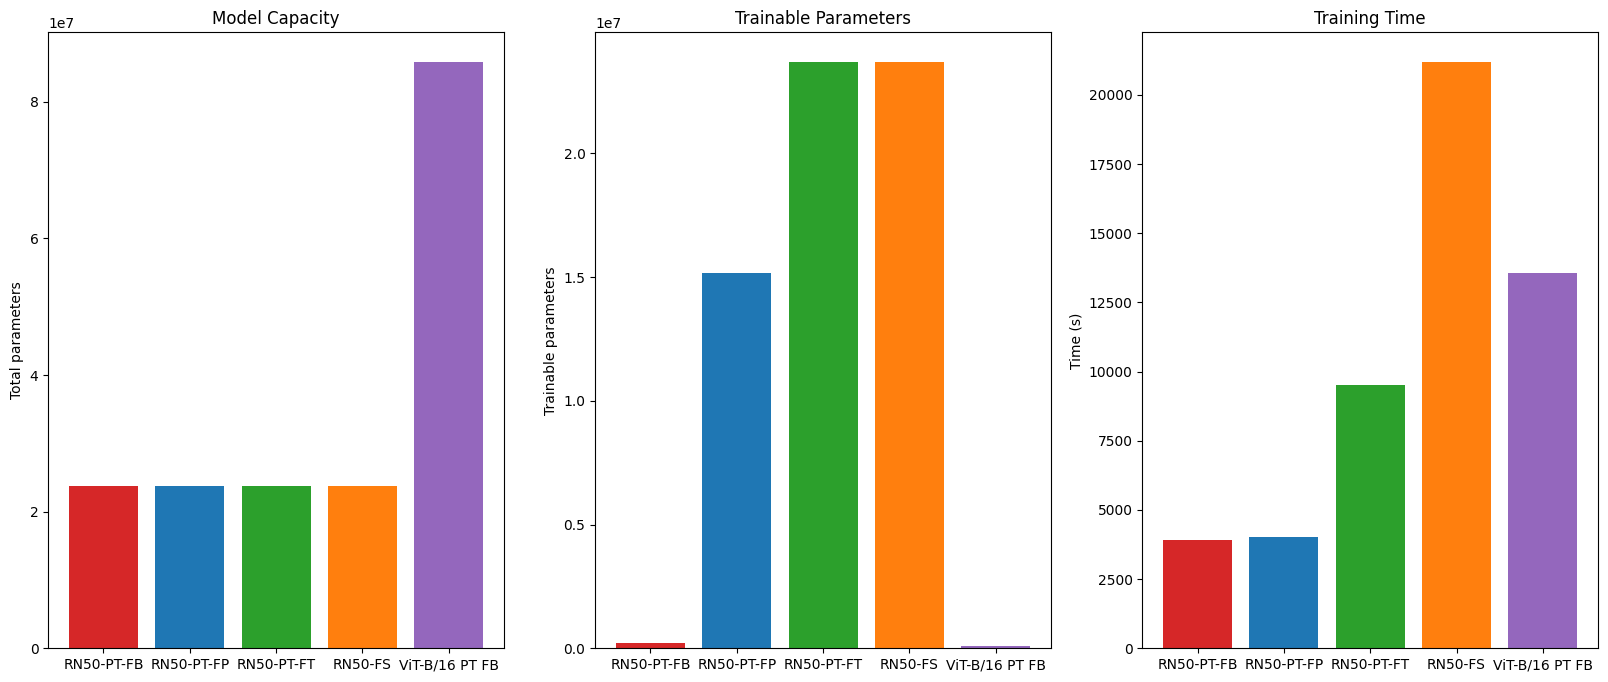

In [365]:
helper_plot_cap_time(predictions, model_names, savepath = "./models/cap_time_comparison.png")

Loss Accuracy of each model

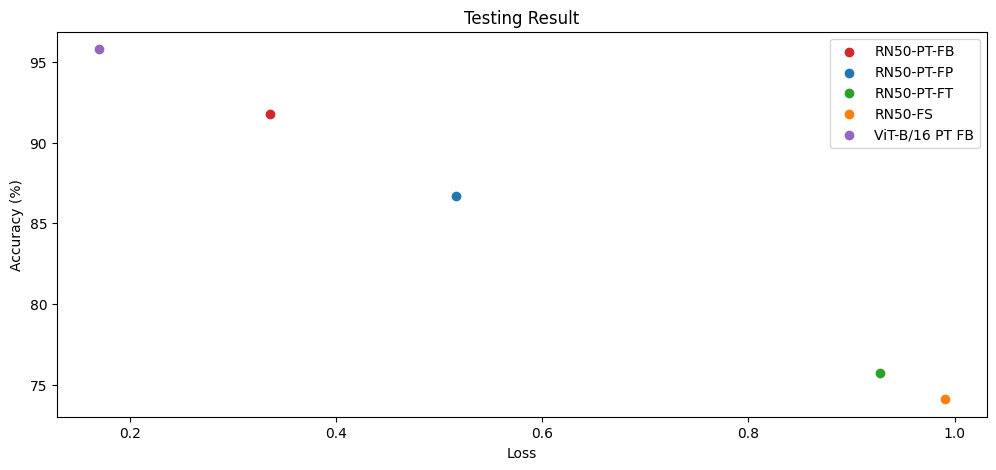

In [373]:
helper_plot_testing_result(predictions, model_names, savepath="./models/testing_result.png")

Loss-Accuracy curve

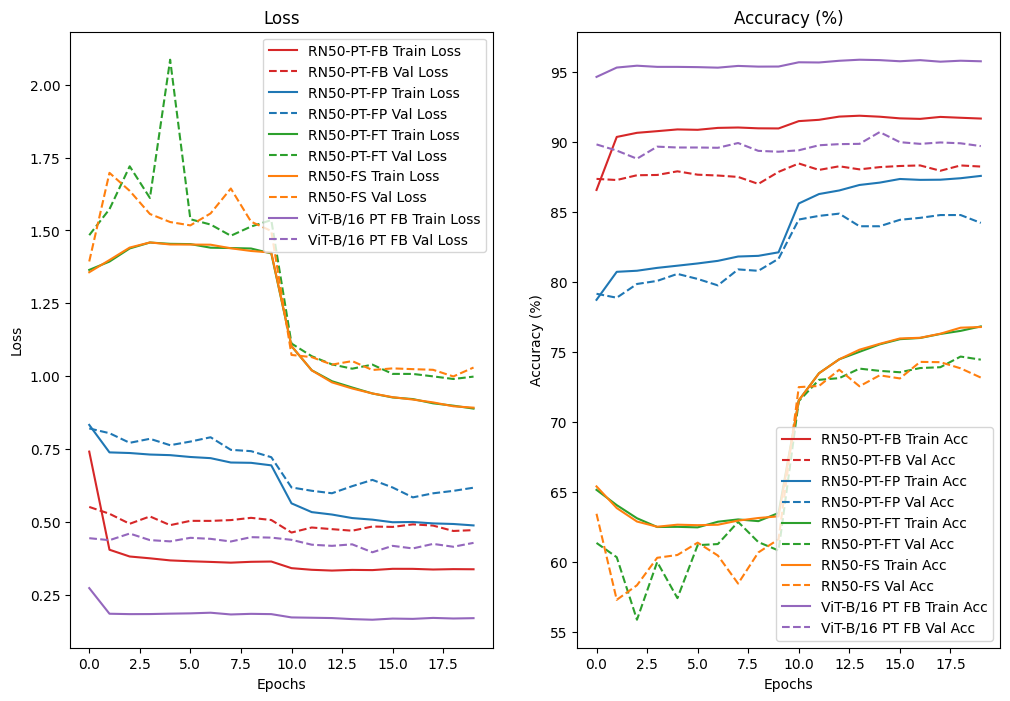

In [369]:
helper_plot_curves(histories, model_names, savepath="./models/curves_all")

Confusion matrix, F1 score

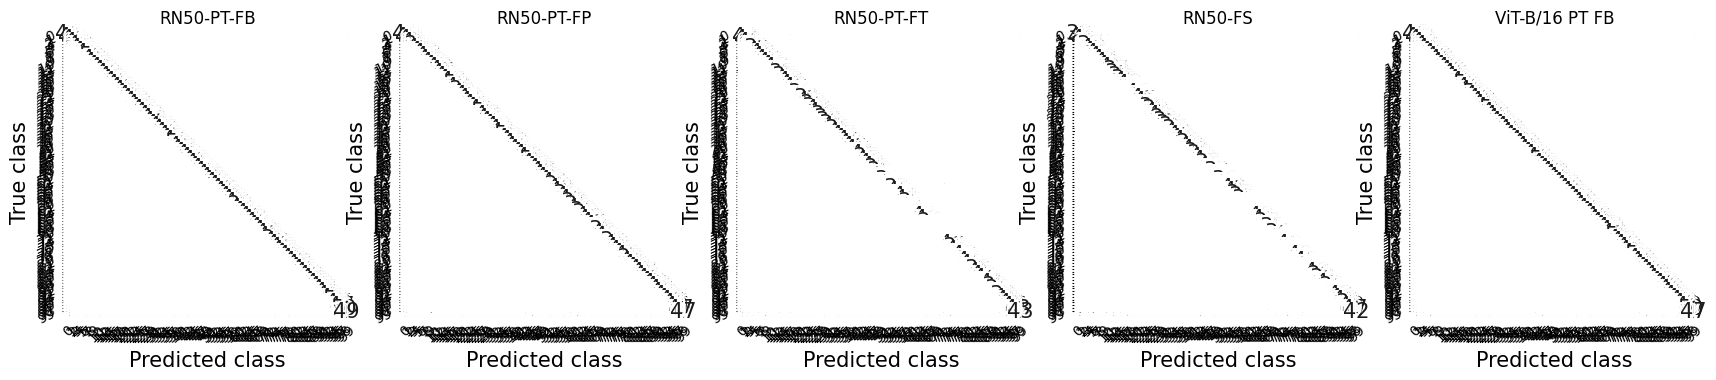

In [370]:
helper_plot_cm(confusionmatrixs, model_names, savepath="./models/confusion_matrix.png")

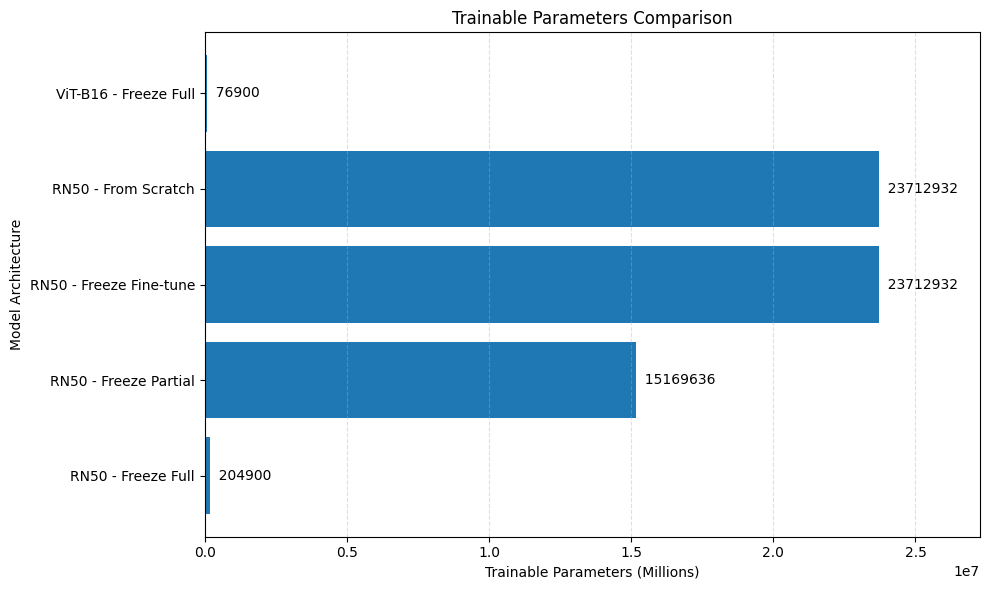

In [215]:
capacity_rn50_freezefull = result_rn50_pt_fb['trainable_params']
capacity_rn50_freezepartial = result_rn50_pt_fp['trainable_params']
capacity_rn50_finetune = result_rn50_pt_ft['trainable_params']
capacity_rn50_fromscratch = result_rn50_fs['trainable_params']
capacity_vitb16_freezefull = result_vitb16_pt_fb['trainable_params']

import matplotlib.pyplot as plt

models = [
    "RN50 - Freeze Full",
    "RN50 - Freeze Partial",
    "RN50 - Freeze Fine-tune",
    "RN50 - From Scratch",
    "ViT-B16 - Freeze Full"
]

capacities = [
    capacity_rn50_freezefull,
    capacity_rn50_freezepartial,
    capacity_rn50_finetune,
    capacity_rn50_fromscratch,
    capacity_vitb16_freezefull
]

# Convert to millions
capacities_m = [value for value in capacities]

plt.figure(figsize=(10, 6))

bars = plt.barh(models, capacities_m)

# Display values
for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"  {width}",
        va="center",
        fontsize=10
    )

plt.xlabel("Trainable Parameters (Millions)")
plt.ylabel("Model Architecture")
plt.title("Trainable Parameters Comparison")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.xlim(0, max(capacities_m) * 1.15)
plt.tight_layout()
plt.show()


### Analyze fail prediction

In [343]:
def get_class_name(class_id):
    return id2clsname.get(int(class_id), "Unknown")

In [391]:
import torch
import torchvision.models as models

model_best_rn50_pt_fb = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_pt_fp = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_pt_ft = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_rn50_fs = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model_best_vitb16_pt_fb = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

# replace head classifier
model_best_rn50_pt_fb.fc = basic_head_classifier(model_best_rn50_pt_fb.fc.in_features, total_cls)
model_best_rn50_pt_fb = model_best_rn50_pt_fb.to(device)

model_best_rn50_pt_fp.fc = basic_head_classifier(model_best_rn50_pt_fp.fc.in_features, total_cls)
model_best_rn50_pt_fp = model_best_rn50_pt_fp.to(device)

model_best_rn50_pt_ft.fc = basic_head_classifier(model_best_rn50_pt_ft.fc.in_features, total_cls)
model_best_rn50_pt_ft = model_best_rn50_pt_ft.to(device)

model_best_rn50_fs.fc = basic_head_classifier(model_best_rn50_fs.fc.in_features, total_cls)
model_best_rn50_fs = model_best_rn50_fs.to(device)

model_best_vitb16_pt_fb.heads.head = basic_head_classifier(model_best_vitb16_pt_fb.heads.head.in_features, total_cls)
model_best_vitb16_pt_fb = model_best_vitb16_pt_fb.to(device)



checkpoint = torch.load("./models/best_rn50_pt_fb_model.pth", map_location=device)
model_best_rn50_pt_fb.load_state_dict(checkpoint['model_state_dict'])

checkpoint = torch.load("./models/best_rn50_pt_fp_model.pth", map_location=device)
model_best_rn50_pt_fp.load_state_dict(checkpoint['model_state_dict'])

checkpoint = torch.load("./models/best_rn50_pt_ft_model.pth", map_location=device)
model_best_rn50_pt_ft.load_state_dict(checkpoint['model_state_dict'])

checkpoint = torch.load("./models/best_rn50_fs_model.pth", map_location=device)
model_best_rn50_fs.load_state_dict(checkpoint['model_state_dict'])

checkpoint = torch.load("./models/best_vitb16_pt_fb_model.pth", map_location=device)
model_best_vitb16_pt_fb.load_state_dict(checkpoint['model_state_dict'])

model_best_rn50_pt_fb.to(device)
model_best_rn50_pt_fp.to(device)
model_best_rn50_pt_ft.to(device)
model_best_rn50_fs.to(device)
model_best_vitb16_pt_fb.to(device)

model_best_rn50_pt_fb.eval()
model_best_rn50_pt_fp.eval()
model_best_rn50_pt_ft.eval()
model_best_rn50_fs.eval()
model_best_vitb16_pt_fb.eval()

C:\Users\pla2hc\AppData\Local\Temp\ipykernel_24820\1364482210.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load("./models/best_rn50_pt_fb_model.pt

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.6622999..0.8099348].


Total samples where all 5 models are wrong: 6


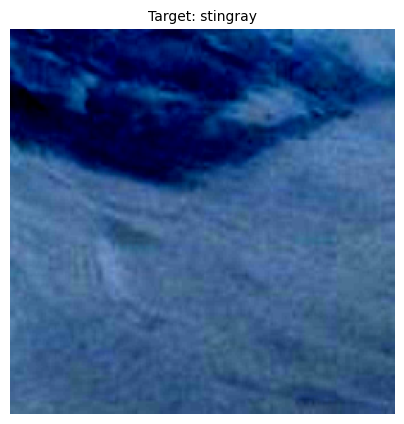

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0182073..2.5877128].



Sample 0
Ground Truth: stingray
RN50 Frozen: seashore, coast, seacoast, sea-coast (31.67%)
RN50 Partial: seashore, coast, seacoast, sea-coast (18.78%)
RN50 Full FT: seashore, coast, seacoast, sea-coast (8.18%)
RN50 Scratch: seashore, coast, seacoast, sea-coast (9.72%)
ViT-B/16: wreck (21.28%)


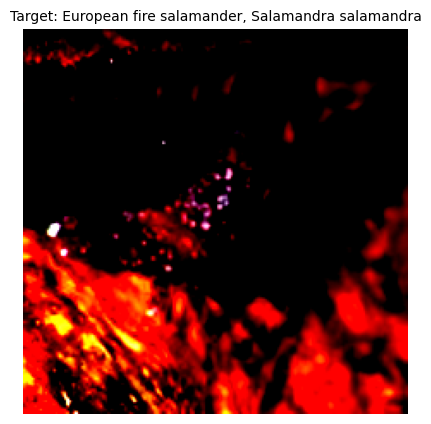

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0665298..2.0776608].



Sample 1
Ground Truth: European fire salamander, Salamandra salamandra
RN50 Frozen: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (89.74%)
RN50 Partial: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (95.54%)
RN50 Full FT: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (65.03%)
RN50 Scratch: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (83.80%)
ViT-B/16: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (47.72%)


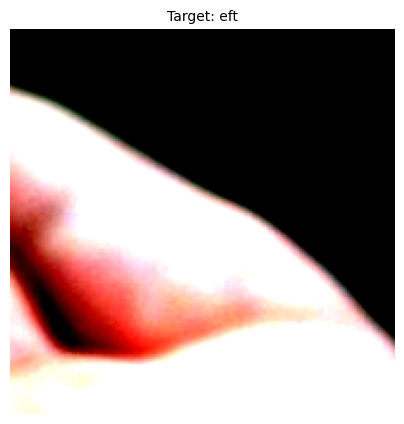

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.843908..2.64].



Sample 2
Ground Truth: eft
RN50 Frozen: scorpion (8.11%)
RN50 Partial: loupe, jeweler's loupe (17.52%)
RN50 Full FT: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (10.41%)
RN50 Scratch: loupe, jeweler's loupe (16.77%)
ViT-B/16: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (26.17%)


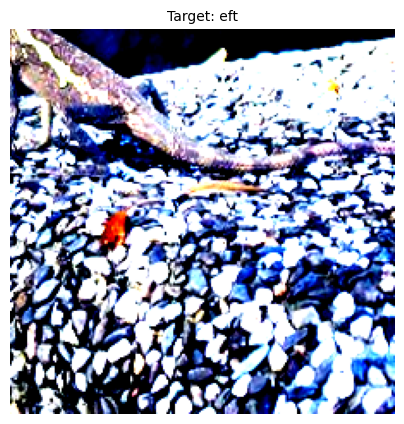

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.68244..2.0262864].



Sample 3
Ground Truth: eft
RN50 Frozen: alligator lizard (88.79%)
RN50 Partial: alligator lizard (21.89%)
RN50 Full FT: stone wall (57.98%)
RN50 Scratch: stone wall (41.36%)
ViT-B/16: alligator lizard (58.84%)


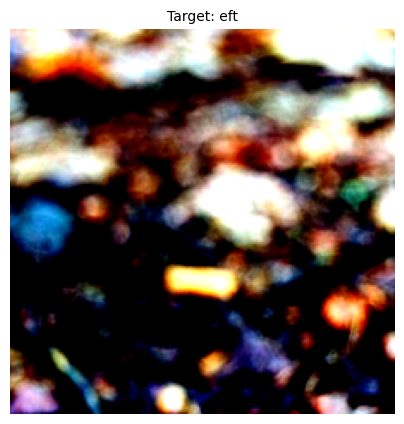

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.2565577].



Sample 4
Ground Truth: eft
RN50 Frozen: slug (20.61%)
RN50 Partial: slug (12.87%)
RN50 Full FT: slug (18.05%)
RN50 Scratch: tiger beetle (15.68%)
ViT-B/16: slug (27.96%)


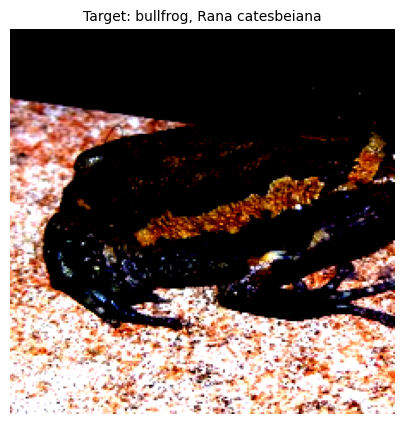


Sample 5
Ground Truth: bullfrog, Rana catesbeiana
RN50 Frozen: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (92.25%)
RN50 Partial: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (89.99%)
RN50 Full FT: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (93.70%)
RN50 Scratch: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (95.66%)
ViT-B/16: tailed frog, bell toad, ribbed toad, tailed toad, Ascaphus trui (81.29%)


In [394]:

# get fail sample from 5 models
import torch

torch.set_printoptions(precision=6, sci_mode=False)

all_fail_inputs = []
all_fail_targets = []

all_fail_out_rn50_pt_fb_labels = []
all_fail_out_rn50_pt_fp_labels = []
all_fail_out_rn50_pt_ft_labels = []
all_fail_out_rn50_fs_labels = []
all_fail_out_vitb16_pt_fb_labels = []

all_fail_out_rn50_pt_fb_score = []
all_fail_out_rn50_pt_fp_score = []
all_fail_out_rn50_pt_ft_score = []
all_fail_out_rn50_fs_score = []
all_fail_out_vitb16_pt_fb_score = []

with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(dataloader_test_rn50_ft):
        if batch_idx <= 2:  # show the fail in specific batches
            inputs, targets = inputs.to(device), targets.to(device)

            out_rn50_pt_fb_logit = model_best_rn50_pt_fb(inputs)
            out_rn50_pt_fb_score = nn.LogSoftmax(dim=1)(out_rn50_pt_fb_logit).exp()*100
            out_rn50_pt_fb_labels = out_rn50_pt_fb_score.max(dim=1)[1]

            out_rn50_pt_fp_logit = model_best_rn50_pt_fp(inputs)
            out_rn50_pt_fp_score = nn.LogSoftmax(dim=1)(out_rn50_pt_fp_logit).exp()*100
            out_rn50_pt_fp_labels = out_rn50_pt_fp_score.max(dim=1)[1]

            out_rn50_pt_ft_logit = model_best_rn50_pt_ft(inputs)
            out_rn50_pt_ft_score = nn.LogSoftmax(dim=1)(out_rn50_pt_ft_logit).exp()*100
            out_rn50_pt_ft_labels = out_rn50_pt_ft_score.max(dim=1)[1]

            out_rn50_fs_logit = model_best_rn50_fs(inputs)
            out_rn50_fs_score = nn.LogSoftmax(dim=1)(out_rn50_fs_logit).exp()*100
            out_rn50_fs_labels = out_rn50_fs_score.max(dim=1)[1]

            out_vitb16_pt_fb_logit = model_best_vitb16_pt_fb(inputs)
            out_vitb16_pt_fb_score = nn.LogSoftmax(dim=1)(out_vitb16_pt_fb_logit).exp()*100
            out_vitb16_pt_fb_labels = out_vitb16_pt_fb_score.max(dim=1)[1]

            # Select samples where ALL 5 models predict incorrectly
            fail_mask = (
                (out_rn50_pt_fb_labels != targets) &
                (out_rn50_pt_fp_labels != targets) &
                (out_rn50_pt_ft_labels != targets) &
                (out_rn50_fs_labels != targets) &
                (out_vitb16_pt_fb_labels != targets)
            )

            # Collect failed samples from current batch
            all_fail_inputs.append(inputs[fail_mask].cpu())
            all_fail_targets.append(targets[fail_mask].cpu())

            all_fail_out_rn50_pt_fb_labels.append(out_rn50_pt_fb_labels[fail_mask].cpu())
            all_fail_out_rn50_pt_fp_labels.append(out_rn50_pt_fp_labels[fail_mask].cpu())
            all_fail_out_rn50_pt_ft_labels.append(out_rn50_pt_ft_labels[fail_mask].cpu())
            all_fail_out_rn50_fs_labels.append(out_rn50_fs_labels[fail_mask].cpu())
            all_fail_out_vitb16_pt_fb_labels.append(out_vitb16_pt_fb_labels[fail_mask].cpu())

            all_fail_out_rn50_pt_fb_score.append(out_rn50_pt_fb_score[fail_mask].cpu())
            all_fail_out_rn50_pt_fp_score.append(out_rn50_pt_fp_score[fail_mask].cpu())
            all_fail_out_rn50_pt_ft_score.append(out_rn50_pt_ft_score[fail_mask].cpu())
            all_fail_out_rn50_fs_score.append(out_rn50_fs_score[fail_mask].cpu())
            all_fail_out_vitb16_pt_fb_score.append(out_vitb16_pt_fb_score[fail_mask].cpu())

        else:
            break


# Combine results from all batches
fail_inputs = torch.cat(all_fail_inputs, dim=0)
fail_targets = torch.cat(all_fail_targets, dim=0)

fail_out_rn50_pt_fb_labels = torch.cat(all_fail_out_rn50_pt_fb_labels, dim=0)
fail_out_rn50_pt_fp_labels = torch.cat(all_fail_out_rn50_pt_fp_labels, dim=0)
fail_out_rn50_pt_ft_labels = torch.cat(all_fail_out_rn50_pt_ft_labels, dim=0)
fail_out_rn50_fs_labels = torch.cat(all_fail_out_rn50_fs_labels, dim=0)
fail_out_vitb16_pt_fb_labels = torch.cat(all_fail_out_vitb16_pt_fb_labels, dim=0)

fail_out_rn50_pt_fb_score = torch.cat(all_fail_out_rn50_pt_fb_score, dim=0)
fail_out_rn50_pt_fp_score = torch.cat(all_fail_out_rn50_pt_fp_score, dim=0)
fail_out_rn50_pt_ft_score = torch.cat(all_fail_out_rn50_pt_ft_score, dim=0)
fail_out_rn50_fs_score = torch.cat(all_fail_out_rn50_fs_score, dim=0)
fail_out_vitb16_pt_fb_score = torch.cat(all_fail_out_vitb16_pt_fb_score, dim=0)

print("Total samples where all 5 models are wrong:", len(fail_inputs))


# print(fail_inputs)
# print(fail_targets)
# print(fail_out_rn50_pt_fp_labels)
# print(fail_out_rn50_pt_ft_labels)
# print(fail_out_rn50_fs_labels)
# print(fail_out_vitb16_pt_fb_labels)


# plot fail samples
import matplotlib.pyplot as plt

for i in range(len(fail_inputs)):
    target_name = get_class_name(fail_targets[i].item())

    predictions = [
        ("RN50 Frozen", fail_out_rn50_pt_fb_labels[i], fail_out_rn50_pt_fb_score[i]),
        ("RN50 Partial", fail_out_rn50_pt_fp_labels[i], fail_out_rn50_pt_fp_score[i]),
        ("RN50 Full FT", fail_out_rn50_pt_ft_labels[i], fail_out_rn50_pt_ft_score[i]),
        ("RN50 Scratch", fail_out_rn50_fs_labels[i], fail_out_rn50_fs_score[i]),
        ("ViT-B/16", fail_out_vitb16_pt_fb_labels[i], fail_out_vitb16_pt_fb_score[i])
    ]

    plt.figure(figsize=(5, 5))
    plt.imshow(fail_inputs[i].permute(1, 2, 0))
    plt.title(f"Target: {target_name}", fontsize=10)

    plt.axis("off")
    plt.savefig(f"./models/fail_sample_{i}.png", dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\nSample {i}")
    print(f"Ground Truth: {target_name}")

    for model_name, pred_label, pred_score in predictions:
        class_name = get_class_name(pred_label.item())
        confidence = pred_score.max(dim=0)[0].item()

        print(f"{model_name}: {class_name} ({confidence:.2f}%)")
